# Projet NUDET : virole de cuve avec liner et chauffage gamma

**057922 Nuclear Design and Technology** · Partie 1 (items 3 à 9), Partie 2, Partie 3

Ce notebook reprend la structure des notebooks G3 et G4 du prof, appliquée à **nos** données (Table 1 du sujet).

**Conventions**
- Températures en **K** dans les calculs, affichées en **°C** pour l'ASME.
- Rayons : $R_w$ = surface mouillée (face interne du liner), $R_i$ = face interne de la cuve (interface liner/cuve), $R_o$ = face externe de la cuve, $R_2$ = face externe de l'isolant.
- La **référence** est le solveur **cylindrique** (même géométrie que Z3ST) ; le solveur **slab** sert de vérification à la main (c'est ce que propose le sujet).

**Corrections de cette version**
- Level A : en fonctionnement normal la cuve est en **compression hydrostatique** ($p$ des deux côtés), la pression ne donne **aucune** intensité de contrainte. Avant, un Lamé en pression interne seule ajoutait ~87 MPa.
- Contraintes calculées avec les données de la **Table 1** ($E$ = 177 GPa, $\alpha$ = 1,54·10⁻⁵ K⁻¹), et plus 190 GPa / 13,5·10⁻⁶.
- Pression externe de calcul fixée à **7,55 MPa** (Partie 0), tableau d'abaques et code cohérents ($B$ = 134,3 MPa à 150 mm).
- CS-5 : la courbe la plus haute est à **345 °C** (pas 370).
- NB-3122.3 : la dispense des 10 % vaut pour l'analyse thermique **et** de contraintes ; on garde le liner parce que c'est **conservatif**.
- Slab contre cylindre : le slab est **non conservatif** d'environ 3 K ici ; la température de design vient du cylindrique (ou de Z3ST).
- Item 9 : la formule de la Fig. 2 et le calcul linéarisé sont réconciliés (pic total adiabatique contre $P+Q$ linéarisé).
- Partie 3 : une seule méthode de dimensionnement du bouclier, sans double comptage du build-up ; réponse corrosion et modèle cohérents ; items 3.4 à 3.8 ajoutés.
- Plus aucune cellule n'écrase les variables globales (`h1`, `U2`, `q0`, ...).

**Plan**
0. Données · 1. Outils · 2. Classification, pression de calcul, épaisseur provisoire · 3. Item 4 · 4. Item 5 · 5. Item 6 (+ Z3ST) · 6. Item 7 · 7. Item 8 · 8. Item 9 · 9. Partie 2 · 10. Partie 3

---
## 0. Données (Table 1 du sujet)

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- Géométrie ------------------------------------------------------------------
L       = 7.0        # m   longueur de la virole cylindrique
D_be    = 2.5        # m   diamètre extérieur du barrel
D_li    = 3.0        # m   diamètre de la surface mouillée (face interne du liner)
t_lin   = 5e-3       # m   épaisseur du liner
t_ins   = 50e-3      # m   épaisseur de l'isolant
k_ins   = 1.4        # W/(m K) conductivité de l'isolant
h_head  = 1.5        # m   profondeur des fonds (pour la longueur non supportée, NB-3133.2)

R_w = D_li/2         # m   surface mouillée = 1.500 m
R_i = R_w + t_lin    # m   face interne de la cuve = 1.505 m

# --- Fluide primaire (pr) --------------------------------------------------------
T_pr    = 487.15     # K   température d'entrée (214 °C)
p_op    = 7.5e6      # Pa  pression de fonctionnement
m_dot   = 3227.0     # kg/s débit massique
cp_pr   = 4534.0     # J/(kg K)
rho_pr  = 852.5      # kg/m3
eta_pr  = 1.259e-4   # Pa s
k_pr    = 0.658      # W/(m K)

# --- Eau du CPP (containment water) ----------------------------------------------
T_cpp   = 343.15     # K   (70 °C)
cp_cpp  = 4172.5     # J/(kg K)
rho_cpp = 981.2      # kg/m3
eta_cpp = 4.06e-4    # Pa s
k_cpp   = 0.666      # W/(m K)
beta_cpp = 5.57e-4   # 1/K
g       = 9.81       # m/s2

# --- Liner austénitique, SA-240 Type 304L ----------------------------------------
k_aus     = 20.1     # W/(m K)
mu_aus    = 24.0     # 1/m  atténuation gamma
E_aus, nu_aus, alpha_aus, rho_aus = 172e9, 0.31, 1.93e-5, 8030.0
T_lim_aus = 425.0    # °C  limite de température du matériau (= 698.15 K)

# --- Cuve ferritique, SA-533 Gr. B Cl. 1 ------------------------------------------
k_fer     = 37.8     # W/(m K)
mu_fer    = 24.0     # 1/m  même atténuation que le liner
E_fer, nu_fer, alpha_fer, rho_fer = 177e9, 0.30, 1.54e-5, 7750.0
T_lim_fer = 370.0    # °C  limite de température du matériau (= 643.15 K)

# --- Source gamma ----------------------------------------------------------------
flux    = 1.5e17     # photons/(m2 s)  -- en m^-2, pas en cm^-2
E_gamma = 6.0        # MeV
B_bu    = 1.4        # facteur de build-up  (NE PAS appeler B : collision avec l'abaque CS-5)
MeV     = 1.602e-13  # J/MeV

C2K = 273.15

---
## 1. Outils

**Solveur slab** (vérification). Différences finies 1D de $-\frac{d}{dx}\left(k\frac{dT}{dx}\right) = q'''(x)$ à travers liner + cuve, $k$ aux demi-points (flux continu à l'interface), Robin des deux côtés :

$$-k\,T'(0) = h_1\,(T_{pr} - T(0)), \qquad k\,T'(t_L + t) = U_2\,(T_{cpp} - T(t_L+t))$$

**Solveur cylindrique** (référence, comme Z3ST). Volumes finis de $\frac{1}{r}\frac{d}{dr}\left(k\,r\frac{dT}{dr}\right) + q'''(r) = 0$, couches empilées depuis la surface mouillée, source exponentielle continue $q'''(r) = q_0'''\,e^{-\int \mu\,dr}$ (item 5). $h$ à la face interne, $U_2$ rapporté à $R_o$ à la face externe.

**Moyenne à travers l'épaisseur** (NCA-2142.1(b), *mean metal temperature*), sur la cuve seule :
$\bar T = \int_{R_i}^{R_o} T\,r\,dr \big/ \int_{R_i}^{R_o} r\,dr$.

**Contraintes** (cylindre creux $a$–$b$, NB-3122.3 : liner négligé car $\le 10\,\%$ de l'épaisseur) :
- thermiques, extrémités libres (Timoshenko) ;
- Lamé avec pression interne $p_i$ **et** externe $p_e$, fonds fermés ;
- linéarisation sur l'épaisseur : membrane + flexion → $P_m$ (pression seule) et $P_m+P_b+Q$ ; la valeur ponctuelle maximale donne le pic total ($+F$).

In [59]:
from scipy.linalg import solve_banded
from scipy.optimize import brentq
import pandas as pd
from scipy.special import k0e      # k0e(z) = K0(z)·e^z, évite les underflows (mu r ≈ 36)

c = lambda T: T - C2K          # K -> °C

def _tridiag(lo, di, up, b):
    # lo[j] = A[j+1, j], up[j] = A[j, j+1]
    ab = np.zeros((3, len(di))); ab[0, 1:] = up; ab[1] = di; ab[2, :-1] = lo
    return solve_banded((1, 1), ab, b)

# ---------------- slab (vérification à la main) -----------------------------------------
def solve_wall(t_v, t_L, q0, h1, U2, mu=mu_fer, mu_L=mu_aus, k_v=k_fer, k_L=k_aus,
               T_in=T_pr, T_out=T_cpp, dx_target=1e-4):
    # x depuis la face interne, T (K), N = indice de l'interface liner/cuve
    N = int(round(t_L/dx_target)); M = int(round(t_v/dx_target)); m = N + M + 1
    x = np.linspace(0, t_L + t_v, m); dx = x[1] - x[0]
    q = np.where(x <= t_L, q0*np.exp(-mu_L*x), q0*np.exp(-mu_L*t_L - mu*(x - t_L)))
    kh = np.where(0.5*(x[1:] + x[:-1]) < t_L, k_L, k_v)
    lo, di, up, b = np.zeros(m-1), np.zeros(m), np.zeros(m-1), np.zeros(m)
    lo[:m-2] = kh[:m-2]; up[1:] = kh[1:]
    di[1:-1] = -(kh[:-1] + kh[1:]); b[1:-1] = -q[1:-1]*dx**2
    di[0], up[0], b[0] = -(kh[0]/dx + h1), kh[0]/dx, -h1*T_in          # Robin, côté interne
    lo[-1], di[-1], b[-1] = -kh[-1]/dx, kh[-1]/dx + U2, U2*T_out        # Robin, côté externe
    return x, _tridiag(lo, di, up, b), N

def T_avg_vessel(x, T, N, t_L):
    r = R_w + x[N:]
    return np.trapezoid(T[N:]*r, r)/np.trapezoid(r, r)

def q_gen(q0, t_L, t_v, mu=mu_fer, mu_L=mu_aus):
    # chaleur générée par unité de surface (W/m2), slab : liner + cuve
    return q0/mu_L*(1 - np.exp(-mu_L*t_L)) + q0*np.exp(-mu_L*t_L)/mu*(1 - np.exp(-mu*t_v))

def summary(x, T, N, t_L):
    Tv = T[N:]; i = int(np.argmax(Tv))
    return dict(T_w=T[0], T_i=T[N], T_o=T[-1], T_max=Tv[i], x_max=x[N:][i] - t_L,
                T_avg=T_avg_vessel(x, T, N, t_L))

# ---------------- cylindrique (référence) --------------------------------------------------
def solve_cyl(R_a, layers, q0, h_in, h_out, T_in=T_pr, T_out=T_cpp, n_per_mm=20):
    # layers = [(épaisseur, k, mu), ...] depuis R_a ; h_out rapporté au rayon externe
    rf = [np.array([R_a])]; ks, mus = [], []
    for t, k, mu in layers:
        n = max(int(round(t*1e3*n_per_mm)), 1)
        rf.append(np.linspace(rf[-1][-1], rf[-1][-1] + t, n + 1)[1:]); ks += [k]*n; mus += [mu]*n
    r = np.concatenate(rf); rc = 0.5*(r[1:] + r[:-1]); dr = np.diff(r)
    k, mu_c = np.array(ks), np.array(mus)
    tau = np.concatenate(([0.0], np.cumsum(mu_c*dr)))[:-1] + 0.5*mu_c*dr
    q = q0*np.exp(-tau)*k0e(mu_c*rc)/k0e(mu_c[0]*R_a)      # q0 K0(mu r)/K0(mu R_a), comme Z3ST
    G = r[1:-1]/(dr[:-1]/(2*k[:-1]) + dr[1:]/(2*k[1:]))
    G_in  = r[0]/(1/h_in + dr[0]/(2*k[0]))     if h_in  > 0 else 0.0
    G_out = r[-1]/(1/h_out + dr[-1]/(2*k[-1])) if h_out > 0 else 0.0
    di = np.zeros(len(rc)); di[:-1] += G; di[1:] += G; di[0] += G_in; di[-1] += G_out
    b = q*rc*dr; b[0] += G_in*T_in; b[-1] += G_out*T_out
    T = _tridiag(-G, di, -G, b)
    q_in  = G_in*(T[0] - T_in)/r[0]            # W/m2 en R_a, > 0 = sort de la paroi
    q_out = G_out*(T[-1] - T_out)/r[-1]        # W/m2 au rayon externe, > 0 = sort de la paroi
    return dict(rc=rc, dr=dr, T=T, q=q, r=r, q_in=q_in, q_out=q_out,
                Ts_in=T_in + q_in/h_in if h_in > 0 else T[0],
                Ts_out=T_out + q_out/h_out if h_out > 0 else T[-1])

def summary_cyl(sol, R_v):
    rc, T, dr = sol['rc'], sol['T'], sol['dr']; v = rc >= R_v
    i = int(np.argmax(T[v]))
    T_i = sol['Ts_in'] if R_v <= sol['r'][0] + 1e-12 else np.interp(R_v, rc, T)
    return dict(T_w=sol['Ts_in'], T_i=T_i, T_o=sol['Ts_out'], T_max=T[v][i], x_max=rc[v][i] - R_v,
                T_avg=np.sum(T[v]*rc[v]*dr[v])/np.sum(rc[v]*dr[v]))

def wall_cyl(q0_w, h_w, liner=True, U=None):
    # la cuve (avec ou sans liner) ; sans liner, la face interne de la cuve est la surface mouillée
    U = U2 if U is None else U
    if liner:
        return solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (t_v, k_fer, mu_fer)], q0_w, h_w, U)
    return solve_cyl(R_i, [(t_v, k_fer, mu_fer)], q0_w, h_w, U)

# ---------------- contraintes ----------------------------------------------------------------
def stress_cyl(rc, T, dr, a, b, E, alpha, nu, p_in=0.0, p_out=0.0):
    Tr = T*rc*dr; Ir = np.cumsum(Tr) - 0.5*Tr; Ib = Tr.sum(); K = alpha*E/(1 - nu)
    s_r = K/rc**2*((rc**2 - a**2)/(b**2 - a**2)*Ib - Ir)
    s_t = K/rc**2*((rc**2 + a**2)/(b**2 - a**2)*Ib + Ir - T*rc**2)
    s_z = K*(2*Ib/(b**2 - a**2) - T)
    A0 = (p_in*a**2 - p_out*b**2)/(b**2 - a**2); B0 = (p_in - p_out)*a**2*b**2/(b**2 - a**2)
    return s_r + A0 - B0/rc**2, s_t + A0 + B0/rc**2, s_z + A0

def _SI(s):    # intensité de contrainte (Tresca) d'un triplet de composantes
    return max(abs(s[0] - s[1]), abs(s[1] - s[2]), abs(s[0] - s[2]))

def level_A(sol, a, b, E, alpha, nu, p_in, p_out):
    # MPa : Pm (pression seule), Pm+Pb+Q linéarisé, pic total ponctuel
    v = sol['rc'] >= a - 1e-12; r, T, dr = sol['rc'][v], sol['T'][v], sol['dr'][v]
    t = b - a; x = r - (a + b)/2
    def lin(sig):
        m = np.sum(sig*dr)/t; fb = 6/t**2*np.sum(sig*x*dr); return m, fb
    sP  = [lin(s) for s in stress_cyl(r, T, dr, a, b, E, 0.0,   nu, p_in, p_out)]
    sPQ = stress_cyl(r, T, dr, a, b, E, alpha, nu, p_in, p_out)
    L = [lin(s) for s in sPQ]
    Pm = _SI([m for m, _ in sP])
    PQ = max(_SI([m + sg*fb for m, fb in L]) for sg in (1, -1))
    tot = max(_SI([s[i] for s in sPQ]) for i in range(len(r)))
    return Pm/1e6, PQ/1e6, tot/1e6

---
## Partie 1

### Item 1 : classification de la cuve
Frontière de pression du circuit primaire : **Quality Group A** (RG 1.26), **Safety Class 1** (ANS 51.1), **Seismic Category I** (RG 1.29) ; règles de **ASME III, Division 1, Subsection NB**.

### Item 2 : pression de calcul (Partie 0)
- **Interne** (perte de l'eau du CPP, la cuve reste à 75 bar) : $p_D = 1{,}1\,p_{op} = 8{,}25$ MPa. La marge de 10 % couvre la pression de tarage des soupapes (NB-7410 : tarage $\le p_D$).
- **Externe** (perte du primaire, le CPP reste pressurisé) : $p_{D,ext} = 7{,}55$ MPa (pression du CPP + colonne d'eau, sans marge de soupape : voir Partie 0, question 3).

> Si vous décidez finalement d'appliquer la même marge en externe (8,25 MPa), changez `p_D_ext` : l'épaisseur requise passe à environ 152–155 mm (voir le tableau ci-dessous) et tout le reste suit.

**Pression interne, NB-3324.1**, $R$ à la face interne du **liner** (NB-3122.2(a)) :
$$t_{min} = \frac{p_D\,R}{S_m - 0{,}5\,p_D}, \qquad S_m = \min\left(\frac{S_u}{3}, \frac{2S_y}{3}\right)$$
Table 2 lue **par ligne** (« not exceeding »), sans interpolation (convention conservative).

In [60]:
# ---- Table 2 : Sm (pression interne, NB-3324.1) ----
T_rows  = np.array([40, 65, 100, 125, 150, 175, 200, 225, 250, 275,
                    300, 325, 350, 375, 400, 425], dtype=float)          # °C
Sy_rows = np.array([345, 332, 323, 318, 314, 309, 305, 302, 299, 296,
                    292, 289, 285, 280, 274, 267], dtype=float)          # MPa
Su      = 550.0
Sm_rows = np.minimum(Su/3.0, 2.0*Sy_rows/3.0)

def row_of(T_C):
    if T_C > T_rows[-1]:
        raise ValueError("hors table : le matériau n'est pas qualifié à cette température")
    return int(np.searchsorted(T_rows, T_C, side="left"))

def Sm_of(T_C):
    return float(Sm_rows[row_of(T_C)])

# ---- CS-5 (ASME II-D, Subpart 3) : B(A, T), valeurs tabulées ----
# log-log en A sur chaque courbe, linéaire en T entre deux courbes ; courbe max 345 °C
CS5 = {
    40:  [(1.99e-4, 20.7), (1.60e-3, 169), (2e-3, 170), (3e-3, 171), (5e-3, 172), (6e-3, 172), (5e-2, 172)],
    95:  [(2.00e-4, 20.7), (1.57e-3, 162), (5e-2, 162)],
    150: [(2.03e-4, 20.7), (1.50e-3, 152), (3e-3, 155), (6e-3, 155), (5e-2, 155)],
    205: [(2.10e-4, 20.7), (1.54e-3, 143), (3e-3, 146), (7e-3, 152), (9e-3, 152), (1e-2, 154), (5e-2, 154)],
    290: [(2.15e-4, 20.7), (1.08e-3, 103), (2e-3, 113), (4e-3, 127), (1e-2, 138), (2e-2, 143), (5e-2, 147)],
    345: [(2.20e-4, 20.7), (1.21e-3, 103), (2e-3, 113), (4e-3, 123), (1e-2, 134), (5e-2, 143)],
}
T_CS5_max = 345.0

def B_CS5(A, T):
    Ts = sorted(CS5)
    if not Ts[0] <= T <= Ts[-1]: raise ValueError(f"T = {T:.0f} °C hors de CS-5 (40-345 °C)")
    def B_at(Tc):
        a, b = np.array(CS5[Tc]).T
        return np.exp(np.interp(np.log(A), np.log(a), np.log(b)))
    i = min(np.searchsorted(Ts, T), len(Ts) - 1); T1, T2 = Ts[max(i - 1, 0)], Ts[i]
    if T == T2 or T1 == T2: return B_at(T2)
    return B_at(T1) + (T - T1)/(T2 - T1)*(B_at(T2) - B_at(T1))

# ---- pressions de calcul ----
p_D     = 1.1*p_op       # Pa, pression de calcul interne
p_D_ext = 7.55e6         # Pa, pression de calcul externe (Partie 0) ; 8.25e6 si marge de soupape

def t_min_int(Sm_MPa, P=p_D, R=R_w):
    return P*R/(Sm_MPa*1e6 - 0.5*P)

T_tentative = 292.0      # °C, température de design provisoire
print(f"p_D = {p_D/1e6:.2f} MPa (interne)   p_D,ext = {p_D_ext/1e6:.2f} MPa (externe)")
print(f"T provisoire {T_tentative:.0f} °C -> ligne {T_rows[row_of(T_tentative)]:.0f} °C, "
      f"Sm = {Sm_of(T_tentative):.1f} MPa -> t_min(int) = {t_min_int(Sm_of(T_tentative))*1e3:.1f} mm")

p_D = 8.25 MPa (interne)   p_D,ext = 7.55 MPa (externe)
T provisoire 292 °C -> ligne 300 °C, Sm = 183.3 MPa -> t_min(int) = 69.1 mm


**Pression externe, NB-3133.** Longueur non supportée (NB-3133.2) : longueur de la virole + **un tiers de la profondeur de chaque fond**. Les fonds ne sont dessinés que schématiquement : on les suppose **hémisphériques**, de profondeur $h \approx R = 1{,}5$ m :
$$L_u = L + 2\cdot\tfrac{1}{3}h = 7 + 2\cdot\tfrac{1}{3}\cdot 1{,}5 = 8\ \text{m}$$
$D_o$ à la face externe de la cuve (NB-3122.2(b)). Pour $D_o/t \ge 10$ : Fig. G donne $A$ ($L_u/D_o$, $D_o/t$), CS-5 donne $B$ (courbe 290 °C, la plus proche des 292 °C provisoires), puis $P_a = 4B/(3\,D_o/t)$.

$A$ tombe **à droite du coude** de CS-5 (zone plastique) : $B$ se lit sur la courbe, et le module $E$ du matériau (note \* du sujet) n'intervient pas. Il n'interviendrait que si $A$ était à gauche du coude ($B = AE/2$).

**Tolérances de fabrication.** On suppose une ovalisation $D_{max} - D_{min} \le 1\,\%$ de $D$ (NB-4221.1) et un écart à la forme circulaire théorique $e$ dans les limites de NB-4221.2. Les abaques de NB-3133 sont établis pour des viroles qui respectent ces tolérances : elles **n'entrent pas** dans la procédure (aucun facteur à appliquer), ce sont des exigences de fabrication sous lesquelles le résultat est valable.

In [61]:
# lectures de A sur la Fig. G (géométrie seule), faites en binôme ; B interpolé dans CS-5 à T_tentative
tab = pd.DataFrame({
    "t [mm]":   [100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
    "A [1e-3]": [2.76, 2.96, 3.17, 3.39, 3.61, 3.84, 4.07, 4.30, 4.54, 4.78, 5.02]})
tab["B [MPa]"] = [B_CS5(a*1e-3, T_tentative) for a in tab["A [1e-3]"]]
tab["D_o [m]"] = 2*(R_i + tab["t [mm]"]/1e3)
tab["L_u/D_o"] = (L + 2*h_head/3)/tab["D_o [m]"]
tab["D_o/t"]   = tab["D_o [m]"]/(tab["t [mm]"]/1e3)
tab["P_a [MPa]"] = 4*tab["B [MPa]"]/(3*tab["D_o/t"])
tab["OK"] = np.where(tab["P_a [MPa]"]*1e6 >= p_D_ext, "oui", "non")
print(tab.to_string(index=False, float_format="{:.3f}".format))

# --- épaisseur minimale exacte : T fixée -> P_a(t) continue croissante, pas d'itération ---
pA = np.polyfit(np.log(tab["t [mm]"]), np.log(tab["A [1e-3]"]*1e-3), 1)   # A(t), loi puissance sur Fig. G
A_of = lambda t_mm: float(np.exp(np.polyval(pA, np.log(t_mm))))

def Pa_of(t_mm, T_C=T_tentative):
    Do_t = 2*(R_i + t_mm*1e-3)/(t_mm*1e-3)
    return 4*B_CS5(A_of(t_mm), T_C)*1e6/(3*Do_t)          # Pa

def t_min_ext_of(p, T_C=T_tentative):
    return brentq(lambda t: Pa_of(t, T_C) - p, 50, 250)   # mm (au-delà de 150 mm : A extrapolé)

# --- épaisseur minimale au mm : on part du premier succès du balayage à 5 mm, on recule, puis on affine ---
t_min_ext = int(tab.loc[tab["OK"] == "oui", "t [mm]"].min())     # premier OK par pas de 5 mm
while Pa_of(t_min_ext - 1) >= p_D_ext:                           # on recule tant que ça tient
    t_min_ext -= 1

print(f"\nde {t_min_ext - 1} à 150 mm par pas de 1 mm (T = {T_tentative:.0f} °C) :")
print(f"{'t [mm]':>7}{'A':>11}{'B [MPa]':>9}{'D_o/t':>8}{'P_a [MPa]':>11}{'marge':>8}  OK")
for t_ in range(t_min_ext - 1, 151):
    Do_t_ = 2*(R_i + t_*1e-3)/(t_*1e-3); A_ = A_of(t_); Pa_ = Pa_of(t_)
    print(f"{t_:7d}{A_:11.3e}{B_CS5(A_, T_tentative):9.1f}{Do_t_:8.2f}{Pa_/1e6:11.3f}"
          f"{100*(Pa_/p_D_ext - 1):+7.1f}%  {'oui' if Pa_ >= p_D_ext else 'non'}")
print(f"-> épaisseur minimale en externe : {t_min_ext} mm")

# --- épaisseur retenue ---
t_v  = 0.150                          # m, épaisseur provisoire retenue
R_o  = R_i + t_v; D_o = 2*R_o
L_u  = L + 2*h_head/3
Do_t, L_Do = D_o/t_v, L_u/D_o
A_chart = A_of(t_v*1e3); B_chart = B_CS5(A_chart, T_tentative)
P_a = 4*B_chart/(3*Do_t)
print(f"\nretenu : t = {t_v*1e3:.0f} mm  D_o = {D_o:.3f} m  L_u/D_o = {L_Do:.2f}  D_o/t = {Do_t:.2f}")
print(f"A = {A_chart:.2e}  B = {B_chart:.1f} MPa  ->  P_a = {P_a:.2f} MPa vs p_D,ext = {p_D_ext/1e6:.2f} MPa "
      f"(marge {100*(P_a*1e6/p_D_ext - 1):+.1f} %)")
print(f"minimum {t_min_ext} mm ; retenu {t_v*1e3:.0f} mm pour couvrir la lecture de A et la baisse de B "
      "à la température de design (item 8)")
print(f"(si p_D,ext = 8.25 MPa : t_min = {t_min_ext_of(8.25e6):.1f} mm, A extrapolé au-delà de 150 mm)")
print(f"\nItem 3c : la pression externe gouverne, {t_v*1e3:.0f} mm contre {t_min_int(Sm_of(T_tentative))*1e3:.1f} mm en interne.")

 t [mm]  A [1e-3]  B [MPa]  D_o [m]  L_u/D_o  D_o/t  P_a [MPa]  OK
    100     2.760  119.238    3.210    2.492 32.100      4.953 non
    105     2.960  120.638    3.220    2.484 30.667      5.245 non
    110     3.170  122.026    3.230    2.477 29.364      5.541 non
    115     3.390  123.400    3.240    2.469 28.174      5.840 non
    120     3.610  124.701    3.250    2.462 27.083      6.139 non
    125     3.840  125.993    3.260    2.454 26.080      6.441 non
    130     4.070  127.054    3.270    2.446 25.154      6.735 non
    135     4.300  127.690    3.280    2.439 24.296      7.007 non
    140     4.540  128.321    3.290    2.432 23.500      7.281 non
    145     4.780  128.922    3.300    2.424 22.759      7.553 oui
    150     5.020  129.497    3.310    2.417 22.067      7.825 oui

de 144 à 150 mm par pas de 1 mm (T = 292 °C) :
 t [mm]          A  B [MPa]   D_o/t  P_a [MPa]   marge  OK
    144  4.731e-03    128.8   22.90      7.498   -0.7%  non
    145  4.780e-03    128.9  

---
### 3. Item 4 : $h_1$, $h_2$, $U_2$

#### 3.1 Film interne, convection forcée (Dittus-Boelter)
$\mathrm{Nu} = 0{,}023\,\mathrm{Re}^{0{,}8}\,\mathrm{Pr}^{0{,}4}$ ; exposant 0,4 : la paroi (chauffée par les gammas) chauffe le fluide ; $D_h = D_{li} - D_{be}$ (= 2 × gap).

In [62]:
A_dc = np.pi/4*(D_li**2 - D_be**2)          # m2, section du downcomer annulaire
D_h  = D_li - D_be                           # m, = 2 x gap
u_pr = m_dot/(rho_pr*A_dc)                   # m/s
Re_pr = rho_pr*u_pr*D_h/eta_pr
Pr_pr = eta_pr*cp_pr/k_pr
Nu_pr = 0.023*Re_pr**0.8*Pr_pr**0.4
h1    = Nu_pr*k_pr/D_h

print(f"gap = {(D_li-D_be)/2*1e3:.0f} mm   A = {A_dc:.3f} m2   u = {u_pr:.2f} m/s   D_h = {D_h:.2f} m")
print(f"Re = {Re_pr:.3e}   Pr = {Pr_pr:.3f}   Nu = {Nu_pr:.0f}   ->   h1 = {h1:.0f} W/(m2 K)\n")
print("Domaine de Dittus-Boelter :")
for lab, val, lo, hi in [("Re > 1e4", Re_pr, 1e4, np.inf), ("0.6 < Pr < 160", Pr_pr, 0.6, 160),
                         ("L/D_h > 10", L/D_h, 10, np.inf)]:
    print(f"  {lab:16} {val:10.4g}   {'OK' if lo <= val <= hi else '*** HORS DOMAINE ***'}")

gap = 250 mm   A = 2.160 m2   u = 1.75 m/s   D_h = 0.50 m
Re = 5.934e+06   Pr = 0.868   Nu = 5698   ->   h1 = 7498 W/(m2 K)

Domaine de Dittus-Boelter :
  Re > 1e4          5.934e+06   OK
  0.6 < Pr < 160       0.8675   OK
  L/D_h > 10               14   OK


### 3.2 Film externe, convection naturelle (McAdams) et $U_2$
$$\mathrm{Nu} = 0{,}13\,(\mathrm{Gr\,Pr})^{1/3}, \qquad \mathrm{Gr} = \frac{g\beta\,\Delta T\,L^3\rho^2}{\mu^2}, \qquad h_2 = \frac{\mathrm{Nu}\,k}{L}$$
avec $\Delta T = 30$ K comme le permet le sujet ; la valeur est **vérifiée a posteriori** à l'item 6 avec le flux sortant calculé.

$U_2$ = isolant + film externe en série, **rapportés à $R_o$** (la cuve est dans le domaine de calcul, on ne la compte pas deux fois) :
$$\frac{1}{U_2} = \frac{R_o\ln(R_2/R_o)}{k_{ins}} + \frac{R_o}{R_2\,h_2}$$

In [63]:
Pr_cpp = eta_cpp*cp_cpp/k_cpp
R_2 = R_o + t_ins

def h2_of(dT, LL=L):
    Ra = g*beta_cpp*max(dT, 1e-6)*LL**3*rho_cpp**2/eta_cpp**2*Pr_cpp
    return 0.13*Ra**(1/3)*k_cpp/LL, Ra

R_ins = R_o*np.log(R_2/R_o)/k_ins                 # m2K/W, rapporté à R_o
def U2_of(h2): return 1.0/(R_ins + R_o/(R_2*h2))

q0 = mu_aus*B_bu*flux*E_gamma*MeV                 # W/m3 (détaillé à l'item 5)

dT_film = 30.0                                    # K, imposé par le sujet
h2, Ra_cpp = h2_of(dT_film)
U2 = U2_of(h2)
print(f"Pr(CPP) = {Pr_cpp:.3f}")
print(f"dT = {dT_film:.0f} K :  Ra = {Ra_cpp:.3e}   h2 = {h2:.0f} W/(m2 K)")
print(f"U2 = {U2:.3f} W/(m2 K), rapporté à R_o = {R_o:.3f} m")
print(f"\nDomaine de McAdams : 1e9 < Ra < 1e12 -> Ra = {Ra_cpp:.2e}  "
      f"{'OK' if 1e9 < Ra_cpp < 1e12 else '*** HORS DOMAINE ***'}")

R_film = R_o/(R_2*h2); R_tot = R_ins + R_film
print(f"\nrésistances : isolant {R_ins:.5f} m2K/W ({100*R_ins/R_tot:.1f} %), film {R_film:.5f} m2K/W ({100*R_film/R_tot:.1f} %)")
print("Sensibilité de U2 à h2 :")
for f in (0.5, 2.0, 10.0, 1e3):
    print(f"   h2 x {f:g}  ->  U2 = {U2_of(f*h2):.3f}  ({100*(U2_of(f*h2)/U2 - 1):+.2f} %)")

Pr(CPP) = 2.544
dT = 30 K :  Ra = 8.353e+14   h2 = 1165 W/(m2 K)
U2 = 27.763 W/(m2 K), rapporté à R_o = 1.655 m

Domaine de McAdams : 1e9 < Ra < 1e12 -> Ra = 8.35e+14  *** HORS DOMAINE ***

résistances : isolant 0.03519 m2K/W (97.7 %), film 0.00083 m2K/W (2.3 %)
Sensibilité de U2 à h2 :
   h2 x 0.5  ->  U2 = 27.136  (-2.26 %)
   h2 x 2  ->  U2 = 28.088  (+1.17 %)
   h2 x 10  ->  U2 = 28.354  (+2.13 %)
   h2 x 1000  ->  U2 = 28.420  (+2.37 %)


**À écrire dans le rapport (item 4).** $h_1$ est dans le domaine de Dittus-Boelter. McAdams est **hors domaine** ($\mathrm{Ra} \sim 10^{15}$, à cause de la hauteur de 7 m), mais l'isolant porte environ 98 % de la résistance de $U_2$ : même un $h_2$ infini ne change $U_2$ que de 2,4 %. Le $\Delta T = 30$ K du sujet est vérifié a posteriori à l'item 6 (l'écart réel est plus faible, sans effet visible sur $U_2$).

---
### 4. Item 5 : la source gamma
$$q_0''' = \mu\,B\,\varphi\,E_\gamma \quad\text{(à la surface mouillée)}, \qquad q'''(x) = q_0'''\,e^{-\mu x}$$
$\mu_{liner} = \mu_{cuve} = 24$ m⁻¹ : une seule exponentielle continue depuis la surface mouillée.

q0''' = 24 x 1.4 x 1.50e+17 x 6.0 x 1.602e-13 = 4.844 MW/m3

source à la surface mouillée (R_w = 1.500 m)         4.844 MW/m3
source à la face interne de la cuve (R_i = 1.505 m)    4.297 MW/m3   (x 0.887)
source à la face externe de la cuve (R_o = 1.655 m)    0.117 MW/m3

longueur de décroissance 1/mu = 41.7 mm dans une cuve de 150 mm -> mu t = 3.60
63 % de l'énergie est déposée dans les 42 premiers mm : le chauffage est une peau.
chaleur générée : 196960 W/m2  (liner 22825, cuve 174135)


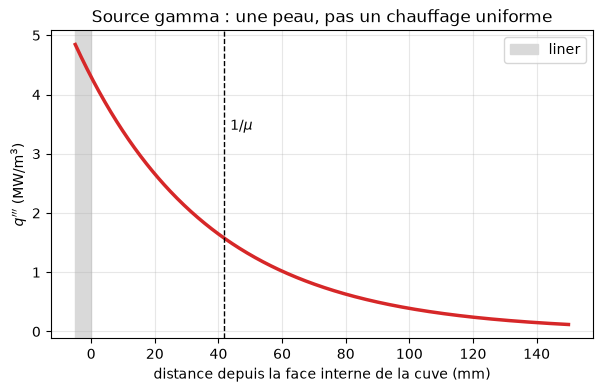

In [64]:
print(f"q0''' = {mu_aus:.0f} x {B_bu} x {flux:.2e} x {E_gamma} x {MeV:.3e} = {q0/1e6:.3f} MW/m3\n")
print(f"source à la surface mouillée (R_w = {R_w:.3f} m)       {q0/1e6:7.3f} MW/m3")
print(f"source à la face interne de la cuve (R_i = {R_i:.3f} m)  {q0*np.exp(-mu_aus*t_lin)/1e6:7.3f} MW/m3"
      f"   (x {np.exp(-mu_aus*t_lin):.3f})")
print(f"source à la face externe de la cuve (R_o = {R_o:.3f} m)  {q0*np.exp(-mu_aus*t_lin - mu_fer*t_v)/1e6:7.3f} MW/m3")
print(f"\nlongueur de décroissance 1/mu = {1e3/mu_fer:.1f} mm dans une cuve de {t_v*1e3:.0f} mm -> mu t = {mu_fer*t_v:.2f}")
print(f"63 % de l'énergie est déposée dans les {1e3/mu_fer:.0f} premiers mm : le chauffage est une peau.")
print(f"chaleur générée : {q_gen(q0, t_lin, t_v):.0f} W/m2  (liner {q_gen(q0, t_lin, 0):.0f}, cuve {q_gen(q0, t_lin, t_v) - q_gen(q0, t_lin, 0):.0f})")

xx = np.linspace(0, t_lin + t_v, 500)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot((xx - t_lin)*1e3, q0*np.exp(-mu_aus*xx)/1e6, lw=2.5, color='tab:red')
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner')
ax.axvline(1e3/mu_fer, ls='--', color='k', lw=1); ax.text(1e3/mu_fer + 2, q0/1e6*0.7, r'$1/\mu$')
ax.set_xlabel('distance depuis la face interne de la cuve (mm)'); ax.set_ylabel(r"$q'''$ (MW/m$^3$)")
ax.set_title("Source gamma : une peau, pas un chauffage uniforme"); ax.grid(alpha=0.3); ax.legend(); plt.show()

---
### 5. Item 6 : $T(r)$ avec et sans liner

**Pourquoi un liner ?** Il protège l'acier ferritique faiblement allié de la **corrosion** par l'eau primaire (et limite le relâchement de produits de corrosion activables). Il ne protège **pas** de l'échauffement, au contraire (voir plus bas).

Cas calculés :
1. cuve + liner, $h_1$ et $U_2$ (cas de l'item 6) ;
2. la même cuve **sans liner** : sa face interne devient la surface mouillée et reçoit $q_0'''$ non atténué ;
3. cuve + liner avec la **face externe adiabatique** ($U_2 = 0$), l'hypothèse des courbes de la Fig. 2.

D'abord le slab (vérification, bilan d'énergie), puis le cylindrique (référence).

In [65]:
# ---------------- slab ----------------
x_L, T_L, N_L = solve_wall(t_v, t_lin, q0, h1, U2)
x_0, T_0, N_0 = solve_wall(t_v, 0.0,   q0, h1, U2)
S_L, S_0 = summary(x_L, T_L, N_L, t_lin), summary(x_0, T_0, N_0, 0.0)

G = q_gen(q0, t_lin, t_v)
q_in_L, q_out_L = h1*(T_L[0] - T_pr), U2*(T_L[-1] - T_cpp)
print("Bilan d'énergie (slab, avec liner) :")
print(f"  généré {G:9.0f} W/m2 | vers le primaire {q_in_L:9.0f} ({100*q_in_L/G:.1f} %) | "
      f"vers le CPP {q_out_L:7.0f} ({100*q_out_L/G:.1f} %) | fermeture {100*(q_in_L + q_out_L)/G - 100:+.3f} %")

# ---------------- cylindrique (référence) ----------------
C_L, C_0, C_a = wall_cyl(q0, h1), wall_cyl(q0, h1, liner=False), wall_cyl(q0, h1, U=0.0)
K_L, K_0, K_a = summary_cyl(C_L, R_i), summary_cyl(C_0, R_i), summary_cyl(C_a, R_i)

rows = (("surface mouillée (°C)", 'T_w'), ("face interne cuve (°C)", 'T_i'), ("face externe cuve (°C)", 'T_o'),
        ("T_max cuve (°C)", 'T_max'), ("moyenne cuve (°C)", 'T_avg'))
print(f"\n{'':30}{'cyl sans liner':>15}{'cyl avec liner':>15}{'slab avec liner':>16}{'slab - cyl':>11}")
for lab, k in rows:
    print(f"{lab:30}{c(K_0[k]):15.1f}{c(K_L[k]):15.1f}{c(S_L[k]):16.1f}{S_L[k] - K_L[k]:+11.1f}")
print(f"{'position T_max (mm de R_i)':30}{K_0['x_max']*1e3:15.1f}{K_L['x_max']*1e3:15.1f}{S_L['x_max']*1e3:16.1f}")
print(f"\nSaut à travers le liner : {K_L['T_i'] - K_L['T_w']:.1f} K sur {t_lin*1e3:.0f} mm.")
print("Le slab est NON conservatif d'environ 3 K : en cylindre, la chaleur qui repart vers l'intérieur traverse\n"
      "une section qui diminue, le gradient est plus fort. La référence est donc le cylindrique (ou Z3ST).")

# ---------------- DeltaT du film externe, a posteriori ----------------
q_R2 = C_L['q_out']*R_o/R_2
dT_real = q_R2/h2
print(f"\nVérification de l'item 4 : flux à la face externe de l'isolant {q_R2:.0f} W/m2 -> dT film = {dT_real:.1f} K "
      f"(30 K supposés) ; U2({dT_real:.0f} K) = {U2_of(h2_of(dT_real)[0]):.3f} contre {U2:.3f} W/(m2 K) : sans effet.")

Bilan d'énergie (slab, avec liner) :
  généré    196960 W/m2 | vers le primaire    187080 (95.0 %) | vers le CPP    9632 (4.9 %) | fermeture -0.126 %

                               cyl sans liner cyl avec liner slab avec liner slab - cyl
surface mouillée (°C)                   239.2          239.2           239.0       -0.2
face interne cuve (°C)                  239.2          283.1           282.7       -0.5
face externe cuve (°C)                  396.1          415.5           416.9       +1.4
T_max cuve (°C)                         402.0          422.6           423.8       +1.1
moyenne cuve (°C)                       372.9          398.2           398.7       +0.5
position T_max (mm de R_i)              108.1          103.2           104.6

Saut à travers le liner : 44.0 K sur 5 mm.
Le slab est NON conservatif d'environ 3 K : en cylindre, la chaleur qui repart vers l'intérieur traverse
une section qui diminue, le gradient est plus fort. La référence est donc le cylindrique (ou Z3

**Vérification à la main du slab (G4 §6).** $T_w = T_{pr} + q''_w/h_1$, puis saut à travers le liner avec un flux qui décroît presque linéairement ($\mu t_L = 0{,}12 \ll 1$) :
$$T_i - T_w \simeq \left(q''_w - \tfrac{1}{2}q_0'''\,t_L\right)\frac{t_L}{k_L}$$

In [66]:
q_w   = G - q_out_L
T_w_h = T_pr + q_w/h1
T_i_h = T_w_h + (q_w - 0.5*q0*t_lin)*t_lin/k_aus
print(f"à la main :            T_w = {c(T_w_h):.1f} °C   T_i = {c(T_i_h):.1f} °C   (borne haute {c(T_w_h + q_w*t_lin/k_aus):.1f} °C)")
print(f"différences finies :   T_w = {c(S_L['T_w']):.1f} °C   T_i = {c(S_L['T_i']):.1f} °C")

à la main :            T_w = 239.0 °C   T_i = 282.6 °C   (borne haute 285.6 °C)
différences finies :   T_w = 239.0 °C   T_i = 282.7 °C


**Deux effets du liner, de sens opposés** :
- **résistance thermique en série** : la chaleur de la cuve, qui repart presque entièrement vers le primaire, traverse 5 mm d'un acier presque deux fois moins conducteur ($k = 20{,}1$ contre $37{,}8$). Tout le profil de la cuve est soulevé d'environ $q''\,t_L/k_L \approx 44$ K. Cet effet joue sur le **niveau** ;
- **atténuation avant la cuve** : le liner absorbe environ 11 % de la source ($e^{-0{,}12} = 0{,}887$), donc l'écart de température à travers la cuve diminue. Cet effet joue sur la **forme**.

Le premier l'emporte : la moyenne et le pic **montent** avec le liner. La surface mouillée ne bouge pas : elle est fixée par $h_1$ et par le flux total sortant.

**NB-3122.3.** Le liner doit être pris en compte dans l'analyse thermique **et** dans l'analyse de contraintes, sauf s'il fait au plus 10 % de l'épaisseur totale. Ici $5/155 = 3{,}2\,\%$ : on **pourrait** le négliger. On le **garde dans le calcul thermique** parce que le négliger (cas « sans liner ») donne une cuve plus froide d'environ 25 °C en moyenne, ce qui serait **non conservatif** pour la température de design. Dans les contraintes, on le néglige (pas de résistance mécanique attribuée, NB-3122.1, et ≤ 10 %).

                               U2 réel  adiabatique    écart
T_max cuve (°C)                  422.6        459.5    +36.9
moyenne cuve (°C)                398.2        422.8    +24.6
face externe (°C)                415.5        459.5    +43.9
-> L'hypothèse adiabatique de la Fig. 2 est conservative (paroi plus chaude).


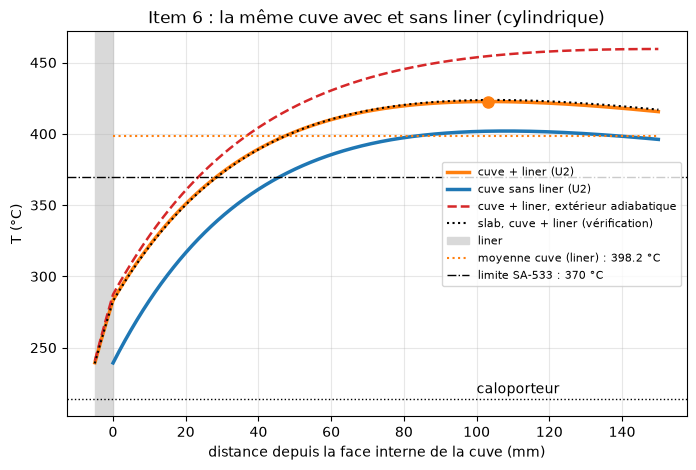

In [67]:
print(f"{'':28}{'U2 réel':>10}{'adiabatique':>13}{'écart':>9}")
for lab, k in (("T_max cuve (°C)", 'T_max'), ("moyenne cuve (°C)", 'T_avg'), ("face externe (°C)", 'T_o')):
    print(f"{lab:28}{c(K_L[k]):10.1f}{c(K_a[k]):13.1f}{K_a[k] - K_L[k]:+9.1f}")
print("-> L'hypothèse adiabatique de la Fig. 2 est conservative (paroi plus chaude).")

xr = lambda sol: (sol['rc'] - R_i)*1e3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xr(C_L), c(C_L['T']), lw=2.5, color='tab:orange', label='cuve + liner (U2)')
ax.plot(xr(C_0), c(C_0['T']), lw=2.5, color='tab:blue', label='cuve sans liner (U2)')
ax.plot(xr(C_a), c(C_a['T']), '--', lw=1.8, color='tab:red', label='cuve + liner, extérieur adiabatique')
ax.plot((x_L - t_lin)*1e3, c(T_L), ':', lw=1.5, color='k', label='slab, cuve + liner (vérification)')
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner')
ax.hlines(c(K_L['T_avg']), 0, t_v*1e3, colors='tab:orange', linestyles=':', label=f"moyenne cuve (liner) : {c(K_L['T_avg']):.1f} °C")
ax.plot(K_L['x_max']*1e3, c(K_L['T_max']), 'o', color='tab:orange', ms=8)
ax.axhline(T_lim_fer, color='k', ls='-.', lw=1, label=f'limite SA-533 : {T_lim_fer:.0f} °C')
ax.axhline(c(T_pr), color='k', ls=':', lw=1); ax.text(100, c(T_pr) + 4, 'caloporteur')
ax.set_xlabel('distance depuis la face interne de la cuve (mm)'); ax.set_ylabel('T (°C)')
ax.set_title('Item 6 : la même cuve avec et sans liner (cylindrique)'); ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.show()

#### 5.2 Comparaison avec Z3ST
L'item 6 demande $T(r)$ **avec Z3ST**. Cas : `~/z3st/cuve_liner` et `~/z3st/cuve_sans_liner` (`gmsh mesh.geo -2`, puis `python3 -m z3st` depuis le dossier du cas).

Paramétrage : les **deux** cartes matériau portent `gamma_heating: 4.845e+6` et `mu_gamma: 24.0`, sans `gamma_inner_radius` : Z3ST compte le profil depuis $R_w$ dans les deux matériaux. Ne **pas** mettre $q_0''' e^{-\mu t_L}$ dans la carte de la cuve.

Z3ST dépose la source avec un profil cylindrique ($K_0(\mu r)/K_0(\mu R_w)$) au lieu de $e^{-\mu x}$ : on attend un écart de l'ordre du kelvin avec notre solveur cylindrique, et environ 3 K avec le slab. La cellule lit `output/fields.vtu` (environnement `z3st` avec `pyvista`) ; sinon, recopier les valeurs dans `Z3ST_manuel`.

In [68]:
CASES = {'avec liner': (os.path.expanduser('~/z3st/cuve_liner'), K_L, t_lin),
         'sans liner': (os.path.expanduser('~/z3st/cuve_sans_liner'), K_0, 0.0)}

# Valeurs Z3ST recopiées à la main (°C) si la lecture automatique échoue ; None = pas renseigné
Z3ST_manuel = {'avec liner': dict(T_max=None, T_avg=None),
               'sans liner': dict(T_max=None, T_avg=None)}

def read_z3st(case, t_L):
    import pyvista as pv, yaml
    gm = yaml.safe_load(open(os.path.join(case, 'geometry.yaml')))
    Ri_, Ro_, Lz_ = gm['Ri'], gm['Ro'], gm['Lz']
    line = pv.read(os.path.join(case, 'output', 'fields.vtu')).sample_over_line(
        (Ri_, Lz_/2, 0.0), (Ro_, Lz_/2, 0.0), resolution=2000)
    ok = np.asarray(line['vtkValidPointMask']).astype(bool) & (np.asarray(line['Temperature']) > 1.0)
    r, T = line.points[ok, 0], np.asarray(line['Temperature'])[ok]
    o = np.argsort(r); r, T = r[o], T[o]
    mv = r >= Ri_ + t_L - 1e-9
    return dict(T_w=T[0], T_i=np.interp(Ri_ + t_L, r, T), T_o=T[-1], T_max=T[mv].max(),
                x_max=r[mv][np.argmax(T[mv])] - (Ri_ + t_L),
                T_avg=np.trapezoid(T[mv]*r[mv], r[mv])/np.trapezoid(r[mv], r[mv]))

Z3 = {}
for lab, (case, S, tL) in CASES.items():
    try:
        Z = read_z3st(case, tL)
    except Exception as e:
        m = Z3ST_manuel[lab]
        if m['T_max'] is None:
            print(f"[{lab}] Z3ST non lu ({type(e).__name__}) et pas de valeurs manuelles : comparaison sautée.")
            continue
        Z = {k: v + C2K for k, v in m.items() if v is not None}
    Z3[lab] = Z
    print(f"[{lab}]{'':14}{'cyl':>9}{'Z3ST':>9}{'écart':>8}")
    for k, nm in (('T_w', 'surface mouillée'), ('T_i', 'face interne cuve'), ('T_max', 'T_max cuve'), ('T_avg', 'moyenne cuve')):
        if k in Z:
            print(f"  {nm:24}{c(S[k]):9.1f}{c(Z[k]):9.1f}{Z[k] - S[k]:+8.1f}")

[avec liner]                    cyl     Z3ST   écart
  surface mouillée            239.2    239.2    +0.0
  face interne cuve           283.1    283.1    -0.0
  T_max cuve                  422.6    422.7    +0.0
  moyenne cuve                398.2    398.2    +0.1
[sans liner]                    cyl     Z3ST   écart
  surface mouillée            239.2    239.6    +0.4
  face interne cuve           239.2    239.6    +0.4
  T_max cuve                  402.0    402.0    +0.0
  moyenne cuve                372.9    372.9    +0.1


---
### 6. Item 7 : flux sans source

Sans source, un seul flux traverse en série le film interne, le liner, la cuve et $U_2$, du primaire (chaud) vers le CPP. En cylindrique, la chaleur **par unité de longueur** est constante : la densité de flux en $R_i$ vaut celle en $R_o$ multipliée par $R_o/R_i$.

Vérification slab : $q'' = (T_{pr} - T_{cpp})/(1/h_1 + t_L/k_L + t/k + 1/U_2)$.

Signe : sans source la chaleur **entre** par la face interne ; avec la source, les **deux** faces évacuent. Dans Z3ST : copier `cuve_liner` en `cuve_sans_source` avec `gamma_heating: 0.0` dans les deux cartes.

Sans source (cylindrique) :
  face interne de la cuve (R_i) :   3.900 kW/m2 vers l'extérieur
  face externe de la cuve (R_o) :   3.547 kW/m2 vers le CPP
  rapport 1.0997 = R_o/R_i = 1.0997 ; slab à la main : 3.567 kW/m2

Avec source (cylindrique) :
  face interne de la cuve (R_i) :   165.5 kW/m2 vers le primaire
  face externe de la cuve (R_o) :    9.59 kW/m2 vers le CPP

Moyenne de la cuve : 204.9 °C sans source, 398.2 °C avec.


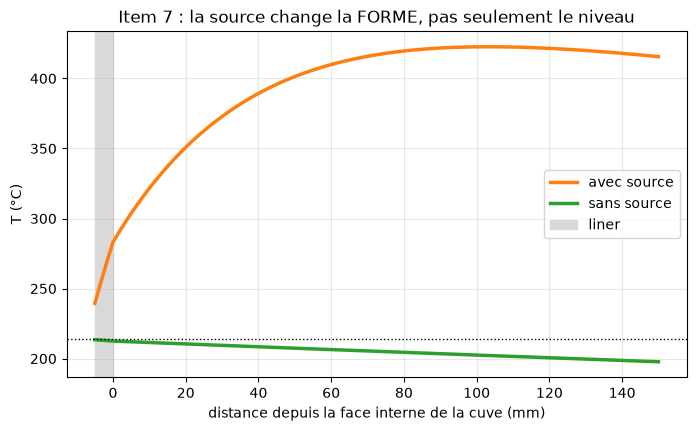

In [69]:
C_n = wall_cyl(0.0, h1); K_n = summary_cyl(C_n, R_i)

def flux_at_Ri(sol):
    # densité de flux conductif en R_i (W/m2), > 0 = vers l'intérieur
    lin = sol['rc'] < R_i
    Q_liner = np.sum(sol['q'][lin]*sol['rc'][lin]*sol['dr'][lin])     # généré dans le liner, par rad
    return (sol['q_in']*R_w - Q_liner)/R_i

q_hand = (T_pr - T_cpp)/(1/h1 + t_lin/k_aus + t_v/k_fer + 1/U2)
print("Sans source (cylindrique) :")
print(f"  face interne de la cuve (R_i) : {-flux_at_Ri(C_n)/1e3:7.3f} kW/m2 vers l'extérieur")
print(f"  face externe de la cuve (R_o) : {C_n['q_out']/1e3:7.3f} kW/m2 vers le CPP")
print(f"  rapport {(-flux_at_Ri(C_n))/C_n['q_out']:.4f} = R_o/R_i = {R_o/R_i:.4f} ; slab à la main : {q_hand/1e3:.3f} kW/m2")
print("\nAvec source (cylindrique) :")
print(f"  face interne de la cuve (R_i) : {flux_at_Ri(C_L)/1e3:7.1f} kW/m2 vers le primaire")
print(f"  face externe de la cuve (R_o) : {C_L['q_out']/1e3:7.2f} kW/m2 vers le CPP")
print(f"\nMoyenne de la cuve : {c(K_n['T_avg']):.1f} °C sans source, {c(K_L['T_avg']):.1f} °C avec.")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xr(C_L), c(C_L['T']), lw=2.5, color='tab:orange', label='avec source')
ax.plot(xr(C_n), c(C_n['T']), lw=2.5, color='tab:green', label='sans source')
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner'); ax.axhline(c(T_pr), color='k', ls=':', lw=1)
ax.set_xlabel('distance depuis la face interne de la cuve (mm)'); ax.set_ylabel('T (°C)')
ax.set_title("Item 7 : la source change la FORME, pas seulement le niveau"); ax.grid(alpha=0.3); ax.legend(); plt.show()

---
### 7. Item 8 : fermeture des conditions de design

**NCA-2142.1(b)**, via **NB-3112.2(a)** : la température de design n'est pas inférieure à la *mean metal temperature through the thickness* maximale ; **NB-3112.2(c)** : le chauffage interne (gammas) est pris en compte. C'est la **moyenne** (le pic va aux contraintes et à la limite matériau), une température de **métal**, en **fonctionnement normal**.

Référence : Z3ST si lu, sinon le solveur cylindrique. Puis :
1. $S_m$ à cette température, pression interne (NB-3324.1 / NB-3221) ;
2. pression externe (NB-3133) : $A$ ne dépend que de la géométrie ; $B$ se relit sur CS-5 **à la température de design** — la courbe la plus haute de CS-5 est à **345 °C** ;
3. pic et moyenne contre la limite matériau (370 °C SA-533, 425 °C pour le 304L).

In [70]:
T_design = c(Z3['avec liner']['T_avg']) if 'avec liner' in Z3 else c(K_L['T_avg'])
T_peak   = c(Z3['avec liner']['T_max']) if 'avec liner' in Z3 else c(K_L['T_max'])
T_peak_liner = C_L['T'][C_L['rc'] < R_i].max()
src = 'Z3ST' if 'avec liner' in Z3 else 'cylindrique'
print(f"température de design (moyenne cuve, avec liner, {src}) : {T_design:.1f} °C ; pic : {T_peak:.1f} °C")

print("\n--- pression interne (NB-3324.1) ---")
for lab, T in (("provisoire", T_tentative), ("design", T_design)):
    print(f"  {lab:11}{T:6.1f} °C -> ligne {T_rows[row_of(T)]:.0f}, Sm = {Sm_of(T):5.1f} MPa"
          f" -> t_min = {t_min_int(Sm_of(T))*1e3:5.1f} mm")
print(f"  {t_v*1e3:.0f} mm >= {t_min_int(Sm_of(T_design))*1e3:.1f} mm -> OK")

T_max_CS5 = 345.0     # °C, courbe la plus haute de CS-5 (Fig. 4)
B_req = 3*(p_D_ext/1e6)*Do_t/4
print("\n--- pression externe (NB-3133) ---")
print(f"  B nécessaire pour 150 mm : B >= 3 p_D,ext (D_o/t)/4 = {B_req:.1f} MPa")
if T_design > T_max_CS5:
    print(f"  T_design = {T_design:.1f} °C > courbe la plus haute de CS-5 ({T_max_CS5:.0f} °C) : B non lisible,")
    print("  le matériau n'est pas couvert à cette température (cohérent avec le dépassement ci-dessous).")

print("\n--- limites de température (NB-1120, NB-3112.4) ---")
for lab, T, lim in (("pic cuve", T_peak, T_lim_fer), ("design (moyenne)", T_design, T_lim_fer),
                    ("pic liner", c(T_peak_liner), T_lim_aus)):
    print(f"  {lab:18}{T:6.1f} °C vs {lim:.0f} °C -> {'OK' if T <= lim else '*** DÉPASSE ***'}")

température de design (moyenne cuve, avec liner, Z3ST) : 398.2 °C ; pic : 422.7 °C

--- pression interne (NB-3324.1) ---
  provisoire  292.0 °C -> ligne 300, Sm = 183.3 MPa -> t_min =  69.1 mm
  design      398.2 °C -> ligne 400, Sm = 182.7 MPa -> t_min =  69.3 mm
  150 mm >= 69.3 mm -> OK

--- pression externe (NB-3133) ---
  B nécessaire pour 150 mm : B >= 3 p_D,ext (D_o/t)/4 = 125.0 MPa
  T_design = 398.2 °C > courbe la plus haute de CS-5 (345 °C) : B non lisible,
  le matériau n'est pas couvert à cette température (cohérent avec le dépassement ci-dessous).

--- limites de température (NB-1120, NB-3112.4) ---
  pic cuve           422.7 °C vs 370 °C -> *** DÉPASSE ***
  design (moyenne)   398.2 °C vs 370 °C -> *** DÉPASSE ***
  pic liner          283.0 °C vs 425 °C -> OK


In [71]:
# --- la boucle de l'item 8 : une paroi plus épaisse est-elle plus froide ? ----------
for f in (0.90, 1.00, 1.03, 1.10):
    s_ = solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (f*t_v, k_fer, mu_fer)], q0, h1, U2)
    S_ = summary_cyl(s_, R_i)
    print(f"cuve {f*t_v*1e3:5.0f} mm : moyenne {c(S_['T_avg']):6.1f} °C   pic {c(S_['T_max']):6.1f} °C")
print("\nUne paroi plus épaisse absorbe plus de gammas et chauffe PLUS : l'épaisseur n'est pas le levier.")
print("Il faut réduire la source qui arrive sur la paroi : c'est le bouclier thermique de la Partie 3.")

cuve   135 mm : moyenne  391.7 °C   pic  416.7 °C
cuve   150 mm : moyenne  398.2 °C   pic  422.6 °C
cuve   154 mm : moyenne  399.8 °C   pic  424.1 °C
cuve   165 mm : moyenne  403.1 °C   pic  426.9 °C

Une paroi plus épaisse absorbe plus de gammas et chauffe PLUS : l'épaisseur n'est pas le levier.
Il faut réduire la source qui arrive sur la paroi : c'est le bouclier thermique de la Partie 3.


**Conclusion de l'item 8.** La température de design (moyenne à travers la cuve avec liner) vaut environ 402 °C et le pic environ 427 °C : les deux dépassent la limite de 370 °C de la SA-533 Gr. B Cl. 1, que NB-3112.4 interdit d'utiliser au-delà. En pression interne la paroi de 150 mm tient largement ($t_{min} \approx 70$ mm) ; en pression externe, CS-5 ne va pas au-delà de 345 °C. Épaissir aggrave la situation : **le design ne se ferme pas sans bouclier thermique (Partie 3).**

---
### 8. Item 9 : vérification Level A (NB-3222)

Température **réelle** du métal (NB-3112.2(a)), pas la température de design.

**Chargement en pression.** En fonctionnement normal, la cuve a **75 bar des deux côtés** (le CPP est à la même pression) : $\sigma_r = \sigma_\theta = \sigma_z = -p$, état hydrostatique, **intensité de contrainte nulle**. La pression ne contribue donc ni à $P_m$ ni à $P+Q$ ; seul le gradient thermique compte.

**Estimation préliminaire (Fig. 2)**, cuve seule ($a = R_i$, $b = R_o$), avec et sans l'atténuation du liner :
$$\sigma = \sigma^T\,\frac{\alpha E\,q_0'''}{k\,(1-\nu)\,\mu^2}$$
La Fig. 2 suppose une face externe **adiabatique** et donne la contrainte thermique **maximale totale** (pic compris). Ce n'est pas la grandeur que NB-3222.2 compare à $3S_m$ : c'est une **borne haute**.

**Calcul linéarisé** sur le champ cylindrique réel ($U_2$) : $P_m+P_b+Q$ (membrane + flexion) $\le 3S_m$, avec $3S_m$ pris comme la moyenne des $S_m$ aux températures haute et basse du cycle (NB-3222.2) ; température basse supposée 40 °C (arrêt à froid).

In [72]:
a_, b_ = R_i, R_o
mu_a, b_a = mu_fer*a_, b_/a_
sigT = 0.67      # lecture Fig. 2 à mu*a ≈ 36 et b/a ≈ 1.10 (interpolation entre les courbes 30 et 40)
print(f"Fig. 2 : mu a = {mu_a:.1f}, b/a = {b_a:.3f} -> sigma_T = {sigT}")

def Sm_cycle(T_hot):
    T_hot = min(T_hot, T_rows[-1])            # au-delà de 425 °C : hors table
    return 0.5*(Sm_of(T_hot) + Sm_of(40.0))
three_Sm = 3*Sm_cycle(c(K_L['T_max']))

for lab, qv in (("sans atténuation du liner", q0), ("avec atténuation du liner", q0*np.exp(-mu_aus*t_lin))):
    sQ = sigT*alpha_fer*E_fer*qv/(k_fer*(1 - nu_fer)*mu_fer**2)/1e6
    print(f"  {lab:28} sigma_max ≈ {sQ:6.0f} MPa (borne haute, pic total adiabatique)")

Pm, PQ, tot = level_A(C_L, a_, b_, E_fer, alpha_fer, nu_fer, p_op, p_op)
print(f"\nChamp cylindrique réel, cuve + liner, p = {p_op/1e6:.1f} MPa des deux côtés :")
print(f"  Pm (pression seule)      = {Pm:6.1f} MPa   (hydrostatique -> 0)")
print(f"  Pm + Pb + Q (linéarisé)  = {PQ:6.1f} MPa   vs 3Sm = {three_Sm:.0f} MPa -> {'OK' if PQ <= three_Sm else 'NON'}")
print(f"  pic total (P + Q + F)    = {tot:6.1f} MPa   (pour la fatigue, NB-3222.4)")
print(f"\nMais T_max = {c(K_L['T_max']):.0f} °C > 370 °C : la vérification Level A n'a pas de sens tant que le matériau"
      "\nest hors de son domaine (NB-3112.4). Le résultat dit seulement que les contraintes ne sont pas le problème.")

Fig. 2 : mu a = 36.1, b/a = 1.100 -> sigma_T = 0.67
  sans atténuation du liner    sigma_max ≈    580 MPa (borne haute, pic total adiabatique)
  avec atténuation du liner    sigma_max ≈    515 MPa (borne haute, pic total adiabatique)

Champ cylindrique réel, cuve + liner, p = 7.5 MPa des deux côtés :
  Pm (pression seule)      =    0.0 MPa   (hydrostatique -> 0)
  Pm + Pb + Q (linéarisé)  =  194.1 MPa   vs 3Sm = 542 MPa -> OK
  pic total (P + Q + F)    =  447.3 MPa   (pour la fatigue, NB-3222.4)

Mais T_max = 423 °C > 370 °C : la vérification Level A n'a pas de sens tant que le matériau
est hors de son domaine (NB-3112.4). Le résultat dit seulement que les contraintes ne sont pas le problème.


**Pourquoi les deux estimations diffèrent** : la Fig. 2 donne le maximum ponctuel de la contrainte thermique avec une face externe adiabatique (paroi plus chaude, gradient plus fort) ; le calcul linéarisé retire la part non linéaire (pic $F$, qui relève de la fatigue) et utilise le vrai $U_2$. La première est une borne haute conservative, la seconde est la grandeur réglementaire.

**À faire avec Z3ST** (demandé par le sujet) : le calcul thermo-mécanique complet sur le cas `cuve_liner`, avec 7,5 MPa appliqués **sur les deux faces**, et la comparaison avec $P+Q$ ci-dessus.

Item 9, cuve, Level A (MPa) ; référence cylindrique = cuve seule (liner négligé, NB-3122.3)
cas            P+Q cyl  P+Q Z3ST    écart   tot cyl  tot Z3ST       eps0
avec liner       194.1     206.8    +6.5%     447.3     423.0  2.753e-03
sans liner       233.9     231.3    -1.1%     520.0     509.8  2.423e-03

3Sm = 542 MPa -> avec liner OK, sans liner OK
  avec liner  membrane (r, θ, z) =   -0.8,  -21.5,  -19.4   flexion =   -9.0, -194.7, -197.2 MPa
  sans liner  membrane (r, θ, z) =   -0.3,   -6.2,   -3.8   flexion =   -9.3, -234.8, -236.7 MPa


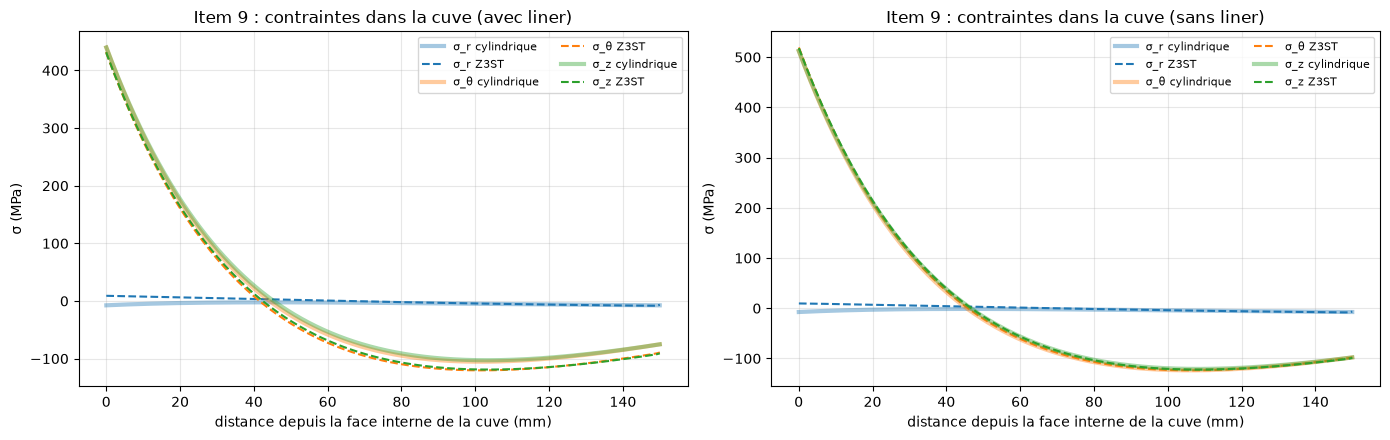

In [73]:
# ===== Item 9 : exploitation des cas Z3ST thermo-mécaniques (~/z3st/nudet/*_meca) =====
# À placer juste après la cellule de l'item 9. Même post-traitement que compare_stress.py :
# Z3ST tourne en déformation plane (eps_z = 0) ; on superpose eps0 uniforme pour retrouver
# un tube long, libre, à fonds fermés (F = p pi Rw^2 - p pi Ro^2), puis on linéarise la cuve.
import yaml
import pyvista as pv

Z3ST_NUDET = os.path.expanduser('~/z3st/nudet')
CASES_MECA = {'avec liner': ('cuve_liner_meca',      C_L),
              'sans liner': ('cuve_sans_liner_meca', C_0)}

def read_z3st_meca(case, p=p_op):
    d = os.path.join(Z3ST_NUDET, case)
    Y = lambda n: yaml.safe_load(open(os.path.join(d, n)))
    g, inp, geo = pv.read(os.path.join(d, 'output', 'fields.vtu')), Y('input.yaml'), Y('geometry.yaml')
    mats = {n: Y(f) for n, f in inp['materials'].items()}; st = mats['steel']
    Rw, Ro, Lz = geo['inner_radius'], geo['outer_radius'], geo['Lz']
    Ri = geo.get('interface_radius', Rw)                     # interface liner/cuve (= Rw sans liner)
    ln = g.sample_over_line((Rw, Lz/2, 0), (Ro, Lz/2, 0), resolution=3000)
    ok = np.asarray(ln['vtkValidPointMask']).astype(bool)
    r, S = ln.points[ok, 0], np.asarray(ln['Stress (points)'])[ok]
    o = np.argsort(r); r, S = r[o], S[o]
    sr, sq, sz = S[:, 0], S[:, 4], S[:, 8]                   # ordre (r, theta, z)
    sz_ps = sz.copy()                                        # brut, déformation plane
    E = np.where(r < Ri, float(mats.get('liner', st)['E']), float(st['E']))
    F = p*np.pi*Rw**2 - p*np.pi*Ro**2                        # effet de fond, fonds fermés
    eps0 = (F - np.trapezoid(sz*2*np.pi*r, r))/np.trapezoid(E*2*np.pi*r, r)
    sz = sz + E*eps0                                         # tube libre de s'allonger
    v = r >= Ri; t = Ro - Ri; x = r[v] - (Ri + Ro)/2
    lin = lambda f: (np.trapezoid(f[v], r[v])/t, 6/t**2*np.trapezoid(f[v]*x, r[v]))
    L = [lin(f) for f in (sr, sq, sz)]
    PQ = max(_SI([m + s*b for m, b in L]) for s in (1, -1))/1e6
    tot = max(_SI([sr[i], sq[i], sz[i]]) for i in np.where(v)[0])/1e6
    return dict(r=r, Ri=Ri, Ro=Ro, sr=sr, sq=sq, sz=sz, sz_ps=sz_ps, eps0=eps0, PQ=PQ, tot=tot,
                m=[m/1e6 for m, _ in L], b=[b/1e6 for _, b in L])

Z3M = {}
for lab, (case, sol) in CASES_MECA.items():
    try:
        Z3M[lab] = read_z3st_meca(case)
    except Exception as e:
        print(f"[{lab}] {case} non lu : {type(e).__name__}: {e}")

if Z3M:
    rows = []
    for lab, (case, sol) in CASES_MECA.items():
        if lab not in Z3M: continue
        Z = Z3M[lab]
        _, PQ_c, tot_c = level_A(sol, R_i, R_o, E_fer, alpha_fer, nu_fer, p_op, p_op)   # liner négligé
        rows.append((lab, PQ_c, Z['PQ'], tot_c, Z['tot'], Z['eps0']))
    print(f"Item 9, cuve, Level A (MPa) ; référence cylindrique = cuve seule (liner négligé, NB-3122.3)")
    print(f"{'cas':12}{'P+Q cyl':>10}{'P+Q Z3ST':>10}{'écart':>9}{'tot cyl':>10}{'tot Z3ST':>10}{'eps0':>11}")
    for lab, a, z, ta, tz, e0 in rows:
        print(f"{lab:12}{a:10.1f}{z:10.1f}{(z - a)/a*100:+8.1f}%{ta:10.1f}{tz:10.1f}{e0:11.3e}")
    print(f"\n3Sm = {three_Sm:.0f} MPa -> " + ", ".join(f"{lab} {'OK' if z <= three_Sm else 'NON'}" for lab, _, z, *_ in rows))
    for lab, Z in Z3M.items():
        print(f"  {lab:11} membrane (r, θ, z) = " + ", ".join(f"{m:6.1f}" for m in Z['m'])
              + "   flexion = " + ", ".join(f"{b:6.1f}" for b in Z['b']) + " MPa")

    # tracé : Z3ST (corrigé fonds fermés) contre cylindrique, dans la cuve
    fig, axs = plt.subplots(1, len(Z3M), figsize=(7*len(Z3M), 4.5), squeeze=False)
    cols = ('tab:blue', 'tab:orange', 'tab:green')
    for ax, (lab, Z) in zip(axs[0], Z3M.items()):
        sol = CASES_MECA[lab][1]; vv = sol['rc'] >= R_i - 1e-12
        ana = stress_cyl(sol['rc'][vv], sol['T'][vv], sol['dr'][vv], R_i, R_o,
                         E_fer, alpha_fer, nu_fer, p_op, p_op)
        xa = (sol['rc'][vv] - R_i)*1e3; xz = (Z['r'] - Z['Ri'])*1e3; k = xz >= 0
        for a, s, nm, col in zip(ana, (Z['sr'], Z['sq'], Z['sz']), ('σ_r', 'σ_θ', 'σ_z'), cols):
            ax.plot(xa, a/1e6, color=col, lw=3, alpha=0.4, label=f'{nm} cylindrique')
            ax.plot(xz[k], s[k]/1e6, color=col, ls='--', lw=1.5, label=f'{nm} Z3ST')
        ax.set_title(f"Item 9 : contraintes dans la cuve ({lab})")
        ax.set_xlabel('distance depuis la face interne de la cuve (mm)'); ax.set_ylabel('σ (MPa)')
        ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
    plt.tight_layout(); plt.show()

---
## Partie 2 : vérification des choix préliminaires

In [74]:
print(f"T_max cuve = {c(K_L['T_max']):.1f} °C   T_design = {T_design:.1f} °C   limite = {T_lim_fer:.0f} °C (NB-1120)")
print(f"-> T_max - limite = {c(K_L['T_max']) - T_lim_fer:+.0f} K : le fluage n'est pas un mode à traiter avec NB (Division 5),")
print("   le matériau est simplement interdit au-delà de 370 °C (NB-3112.4) : composant NON admissible sans bouclier.")

T_max cuve = 422.6 °C   T_design = 398.2 °C   limite = 370 °C (NB-1120)
-> T_max - limite = +53 K : le fluage n'est pas un mode à traiter avec NB (Division 5),
   le matériau est simplement interdit au-delà de 370 °C (NB-3112.4) : composant NON admissible sans bouclier.


| Réponse de la Partie 0 | Statut | Commentaire |
|---|---|---|
| ASME III, Div. 1, Subsection NB | confirmée | frontière de pression de classe 1 |
| Pas de fluage, $S_m$ indépendant du temps | **non confirmée sans bouclier** | $T_{max} \approx 427$ °C > 370 °C ; confirmée avec le bouclier (Partie 3) |
| $p_D = 8{,}25$ MPa (interne) | confirmée | $t_{min} \approx 70$ mm, non dimensionnant |
| $p_{D,ext} = 7{,}55$ MPa (externe) | confirmée | dimensionnant : 150 mm |
| $T_D$ provisoire 292 °C | **à changer** | 402 °C sans bouclier ; environ 300 °C avec (Partie 3) |

**Item 9** : les contraintes Level A ne sont pas limitantes ($P+Q$ linéarisé bien sous $3S_m$, pression hydrostatique sans effet) ; c'est la **température** qui interdit le design et impose le bouclier thermique.

---
## Partie 3 : bouclier thermique

### 3.1 Critères de choix du matériau
Fonction : **atténuer les gammas** avant la cuve. Critères : coefficient d'atténuation élevé (densité élevée, $Z$ élevé) ; bonne **conductivité** thermique (il chauffe lui-même : un pic interne faible) ; faible dilatation et bonne tenue mécanique à chaud (contraintes thermiques) ; compatibilité avec l'eau primaire (corrosion, relâchement de produits activables) ; tenue sous irradiation ; coût et soudabilité. Le sujet impose la SA-533 Gr. B Cl. 1 ($\mu = 24$ m⁻¹).

### 3.2 Classification
Le bouclier n'est **pas** une frontière de pression : il ne relève pas des Quality Groups A–D. C'est une **structure interne** du réacteur (ASME III, Subsection NG, *internal structure*), **non classée** au sens de la sûreté de la frontière de pression, mais **Seismic Category I** : sa chute ou sa rupture pourrait endommager le cœur ou bloquer l'écoulement.

### 3.3 Corrosion
**Non**, pas comme la cuve : le bouclier n'est pas une frontière de pression et sa ruine par corrosion ne compromet pas le confinement. Une **surépaisseur de corrosion** suffit pour garder son atténuation sur la durée de vie. (La question 1 de la Partie 4 traite justement le cas où on voudrait aussi le protéger.) On le modélise donc **sans liner**.

### Méthode
Le bouclier coaxial partage le downcomer en **deux canaux en parallèle** (barrel–bouclier, bouclier–liner) ; le débit se répartit pour égaliser les pertes de charge :
$$\Delta p_j = \left(f_j\frac{L}{D_{h,j}} + K\right)\frac{\rho u_j^2}{2}, \qquad f_j = 0{,}184\,\mathrm{Re}_j^{-0{,}2}, \qquad K = 1{,}5$$
Pour la cuve, le bouclier change deux choses : la source à la surface mouillée devient $q_0'''\,e^{-\mu_s t_s}$ (lame d'eau supposée transparente : conservatif) et le film devient $h$ du canal bouclier–liner.

**Build-up** : le $B = 1{,}4$ est déjà dans $q_0'''$ (Table 1). On ne le réapplique pas ; en **sensibilité** seulement, on prend $\min(1,\ 1{,}4\,e^{-\mu t_s})$ pour couvrir le build-up dans le bouclier.


T_max cuve, build-up 1.4 (°C)
  R_s \ t_s (mm)       5      10      15      20      25      30      35      40
            1270   421.3   420.9   415.4   390.9   369.3   350.1   333.2   318.2
            1280   421.1   420.7   415.1   390.7   369.1   350.0   333.0   318.1
            1290   420.9   420.4   414.9   390.5   368.9   349.8   332.9   318.0
            1300   420.7   420.2   414.7   390.3   368.8   349.7   332.8   317.9
            1310   420.5   420.0   414.5   390.2   368.6   349.5   332.7   317.8
            1320   420.3   419.9   414.4   390.0   368.4   349.4   332.5   317.7
            1330   420.1   419.7   414.2   389.8   368.3   349.3   332.4   317.5
            1340   419.9   419.5   414.0   389.6   368.1   349.1   332.3   317.4
            1350   419.7   419.3   413.8   389.5   368.0   349.0   332.2   317.3
            1360   419.5   419.0   413.6   389.3   367.8   348.8   332.0   317.2
            1370   419.3   418.8   413.4   389.1   367.7   348.7   331.9   317

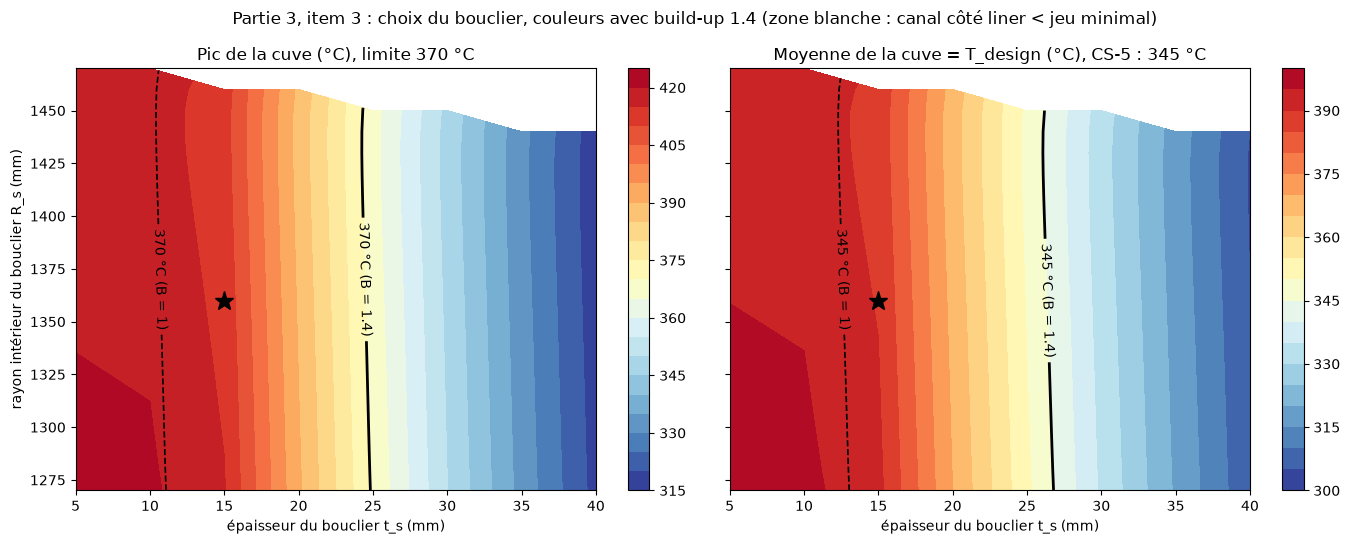

In [75]:
R_bar  = D_be/2
mu_s = mu_fer
K_form = 1.5
gap_min = 0.02            # m, jeu minimal de chaque canal (fabrication, montage)

def channel(R_in, R_out, m_ch):
    gap = R_out - R_in; A_ch = np.pi*(R_out**2 - R_in**2)
    Dh = 2*gap
    u = m_ch/(rho_pr*A_ch); Re = rho_pr*u*Dh/eta_pr
    h = 0.023*Re**0.8*Pr_pr**0.4*k_pr/Dh
    f = 0.184*Re**-0.2
    dp = (f*L/Dh + K_form)*rho_pr*u**2/2
    return dict(gap=gap, u=u, Re=Re, h=h, dp=dp, ok_DB=Re > 1e4 and 0.6 < Pr_pr < 160 and L/Dh > 10)

def split(R_s, t_s):
    sh = brentq(lambda s: channel(R_bar, R_s, s*m_dot)['dp'] - channel(R_s + t_s, R_w, (1 - s)*m_dot)['dp'],
                1e-3, 1 - 1e-3)
    return sh, channel(R_bar, R_s, sh*m_dot), channel(R_s + t_s, R_w, (1 - sh)*m_dot)

def with_shield(R_s, t_s, B_sh=1):
    # B_sh : build-up dans le bouclier ; mu = 24 m-1 est l'atténuation en faisceau étroit,
    # exp(-mu t) seul ne compte que les photons non diffusés -> B_sh = 1.4 est le cas de dimensionnement
    sh, ci, co = split(R_s, t_s)
    f = min(1.0, B_sh*np.exp(-mu_s*t_s))
    sol = wall_cyl(f*q0, co['h'])
    return dict(share=sh, ci=ci, co=co, f=f, sol=sol, S=summary_cyl(sol, R_i))

# ===== Partie 3, item 3 : balayage (R_s, t_s) du bouclier =====
# Critères : T_max <= 370 °C (NB-3112.4) et T_moy <= 345 °C (plus haute courbe de CS-5, pression externe).
# Cas de dimensionnement : B = 1 (le 1.4 de la Table 1 est déjà dans q0, mu est effectif) ; B = 1.4 en enveloppe.
B_DIM = 1.4
R_s_list = np.round(np.arange(R_bar + gap_min, R_w - gap_min, 0.01), 3)   # m, pas de 1 cm, jeu mini des deux côtés
t_s_list = np.arange(5, 41, 5)*1e-3                                        # m

SW = {}
for R_s_ in R_s_list:
    for t_ in t_s_list:
        if R_s_ + t_ > R_w - gap_min: continue           # canal côté liner trop étroit
        W1, WB = with_shield(R_s_, t_, 1.0), with_shield(R_s_, t_, B_DIM)
        SW[R_s_, t_] = dict(Tmax=c(W1['S']['T_max']), Tavg=c(W1['S']['T_avg']),
                            TmaxB=c(WB['S']['T_max']), TavgB=c(WB['S']['T_avg']),
                            h=W1['co']['h'], dp=W1['co']['dp'])

for nom, cle in ((f"T_max cuve, build-up {B_DIM} (°C)", 'TmaxB'), (f"T_moy cuve, build-up {B_DIM} (°C)", 'TavgB'),
                 ("T_max cuve, B = 1 (°C)", 'Tmax'), ("T_moy cuve, B = 1 (°C)", 'Tavg')):
    print(f"\n{nom}\n{'R_s \\ t_s (mm)':>16}" + "".join(f"{t_*1e3:8.0f}" for t_ in t_s_list))
    for R_s_ in R_s_list:
        print(f"{R_s_*1e3:16.0f}" + "".join(f"{SW[R_s_, t_][cle]:8.1f}" if (R_s_, t_) in SW else f"{'-':>8}"
                                         for t_ in t_s_list))

# épaisseur minimale par critère, au milieu du downcomer
R_mid = round((R_bar + R_w)/2, 2)
print(f"\nÉpaisseur minimale à R_s = {R_mid*1e3:.0f} mm :")
for nom, cle, lim in (("T_max <= 370 °C", 'S_max', T_lim_fer), ("T_moy <= 345 °C", 'S_avg', 345.0)):
    for Bs in (1.0, B_DIM):
        k_ = 'T_max' if cle == 'S_max' else 'T_avg'
        t_min_ = brentq(lambda t: c(with_shield(R_mid, t, Bs)['S'][k_]) - lim, 1e-3, R_w - gap_min - R_mid)
        print(f"  {nom:18} B = {Bs:.1f} : t_s >= {t_min_*1e3:5.1f} mm")

# cartes (t_s, R_s) : couleur = cas de dimensionnement (build-up) ; trait plein = limite avec build-up,
# tirets = même limite avec B = 1
ts_mm = t_s_list*1e3; Rs_mm = np.array(R_s_list)*1e3
grid = lambda cle: np.array([[SW[R_, t_][cle] if (R_, t_) in SW else np.nan for t_ in t_s_list] for R_ in R_s_list])
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax_, cle, lim, nom in ((axs[0], 'Tmax', T_lim_fer, 'Pic de la cuve (°C), limite 370 °C'),
                           (axs[1], 'Tavg', 345.0, 'Moyenne de la cuve = T_design (°C), CS-5 : 345 °C')):
    cf = ax_.contourf(ts_mm, Rs_mm, grid(cle + 'B'), levels=20, cmap='RdYlBu_r')
    cs = ax_.contour(ts_mm, Rs_mm, grid(cle + 'B'), levels=[lim], colors='k', linewidths=2)
    ax_.clabel(cs, fmt=f'{lim:.0f} °C (B = {B_DIM})')
    cs1 = ax_.contour(ts_mm, Rs_mm, grid(cle), levels=[lim], colors='k', linewidths=1.2, linestyles='--')
    ax_.clabel(cs1, fmt=f'{lim:.0f} °C (B = 1)')
    if 't_s' in globals() and 'R_s' in globals():
        ax_.plot(t_s*1e3, R_s*1e3, 'k*', ms=14)
    fig.colorbar(cf, ax=ax_)
    ax_.set_title(nom); ax_.set_xlabel('épaisseur du bouclier t_s (mm)')
axs[0].set_ylabel('rayon intérieur du bouclier R_s (mm)')
plt.suptitle(f'Partie 3, item 3 : choix du bouclier, couleurs avec build-up {B_DIM} '
             '(zone blanche : canal côté liner < jeu minimal)')
plt.tight_layout(); plt.show()

 Deux limites de température s'appliquent. D'une part, la température maximale du métal ne doit pas dépasser 370 °C (NB-3112.4). D'autre part, la température de calcul, c'est-à-dire la moyenne à travers l'épaisseur (NCA-2142.1(b)), ne doit pas dépasser 345 °C, la courbe la plus haute de CS-5 : au-delà, on ne peut plus effectuer la vérification en pression externe, qui dimensionne la virole. Comme le pic dépasse la moyenne de moins de 25 K (environ 11 K avec le bouclier), c'est le critère sur la température moyenne qui gouverne.

In [76]:
t_s, R_s = 0.015, 1.36
WS = with_shield(R_s, t_s)               # cas de dimensionnement : B = 1.4 déjà dans q0
ci, co, K_s = WS['ci'], WS['co'], WS['S']
print(f"bouclier : R_s = {R_s*1e3:.0f} mm, t_s = {t_s*1e3:.0f} mm ; canaux {ci['gap']*1e3:.0f} / {co['gap']*1e3:.0f} mm")
print(f"débit : {100*WS['share']:.1f} % côté barrel, {100*(1 - WS['share']):.1f} % côté liner ; dp = {ci['dp']/1e3:.2f} kPa")
print(f"h canal interne = {ci['h']:.0f}, h canal externe = {co['h']:.0f} W/(m2 K) ; "
      f"Re = {ci['Re']:.2e} / {co['Re']:.2e} ; Dittus-Boelter {'OK' if ci['ok_DB'] and co['ok_DB'] else 'NON'}")
print(f"cuve (build-up 1.4) : pic {c(K_s['T_max']):.1f} °C, moyenne {c(K_s['T_avg']):.1f} °C -> marges ")
print(f"cuve (design) : pic {c(K_s['T_max']):.1f} °C, moyenne {c(K_s['T_avg']):.1f} °C -> marges "
      f"{T_lim_fer - c(K_s['T_max']):.0f} K (pic / 370) et {345 - c(K_s['T_avg']):.0f} K (moyenne / 345)")
WSb = with_shield(R_s, t_s, 1.4)
print(f"(enveloppe, build-up réappliqué dans le bouclier : pic {c(WSb['S']['T_max']):.1f} °C, "
      f"moyenne {c(WSb['S']['T_avg']):.1f} °C)")

bouclier : R_s = 1360 mm, t_s = 15 mm ; canaux 110 / 125 mm
débit : 44.1 % côté barrel, 55.9 % côté liner ; dp = 2.63 kPa
h canal interne = 9231, h canal externe = 9087 W/(m2 K) ; Re = 2.76e+06 / 3.17e+06 ; Dittus-Boelter OK
cuve (build-up 1.4) : pic 353.3 °C, moyenne 336.9 °C -> marges 
cuve (design) : pic 353.3 °C, moyenne 336.9 °C -> marges 17 K (pic / 370) et 8 K (moyenne / 345)
(enveloppe, build-up réappliqué dans le bouclier : pic 413.6 °C, moyenne 389.6 °C)


### 3.4 Profil de température dans le bouclier
Slab (comme demandé), source $q_0'''\,e^{-\mu x}$ depuis la face interne (le flux arrive sur le bouclier), Dittus-Boelter sur chaque face avec le débit de chaque canal, les deux fluides à $T_{pr}$.

chaleur générée dans le bouclier : 61.0 kW/m2 ; vers le canal interne 31.5, vers le canal externe 29.1 kW/m2
face interne 217.4 °C | face externe 217.2 °C | max 220.3 °C à 7.1 mm de la face interne | moyenne 219.3 °C


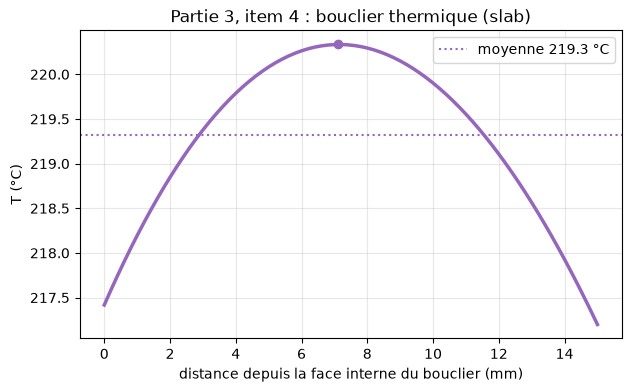

In [77]:
xs, Ts, _ = solve_wall(t_s, 0.0, q0, ci['h'], co['h'], T_in=T_pr, T_out=T_pr)
i_m = int(np.argmax(Ts)); Ts_avg = np.trapezoid(Ts, xs)/t_s
Gs = q0/mu_s*(1 - np.exp(-mu_s*t_s))
print(f"chaleur générée dans le bouclier : {Gs/1e3:.1f} kW/m2 ; vers le canal interne {ci['h']*(Ts[0] - T_pr)/1e3:.1f}, "
      f"vers le canal externe {co['h']*(Ts[-1] - T_pr)/1e3:.1f} kW/m2")
print(f"face interne {c(Ts[0]):.1f} °C | face externe {c(Ts[-1]):.1f} °C | max {c(Ts[i_m]):.1f} °C à {xs[i_m]*1e3:.1f} mm "
      f"de la face interne | moyenne {c(Ts_avg):.1f} °C")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs*1e3, c(Ts), lw=2.5, color='tab:purple'); ax.plot(xs[i_m]*1e3, c(Ts[i_m]), 'o', color='tab:purple')
ax.axhline(c(Ts_avg), ls=':', color='tab:purple', label=f'moyenne {c(Ts_avg):.1f} °C')
ax.set_xlabel('distance depuis la face interne du bouclier (mm)'); ax.set_ylabel('T (°C)')
ax.set_title('Partie 3, item 4 : bouclier thermique (slab)'); ax.grid(alpha=0.3); ax.legend(); plt.show()

### 3.5 Conditions de design du bouclier
- **Pression** : les deux canaux partent du même plenum et arrivent au même plenum, la différence de pression à travers le bouclier est de l'ordre de la perte de charge des canaux (quelques kPa). La pression absolue (75 bar) agit sur les deux faces : état hydrostatique, sans contrainte déviatorique. On prend comme **pression différentielle de design** une valeur forfaitaire de 0,1 MPa, qui couvre largement $\Delta p$ et les transitoires d'écoulement.
- **Température** : moyenne maximale à travers l'épaisseur, arrondie au-dessus.

In [78]:
dp_design_sh = 0.1e6
T_design_sh = np.ceil(c(Ts_avg)/5)*5
print(f"bouclier : dp_design = {dp_design_sh/1e6:.1f} MPa (dp réel {ci['dp']/1e3:.1f} kPa), T_design = {T_design_sh:.0f} °C, "
      f"pic {c(Ts.max()):.0f} °C vs limite {T_lim_fer:.0f} °C -> {'OK' if c(Ts.max()) <= T_lim_fer else 'NON'}")

bouclier : dp_design = 0.1 MPa (dp réel 2.6 kPa), T_design = 220 °C, pic 220 °C vs limite 370 °C -> OK


### 3.6 Contraintes dans le bouclier (Level A)
Cylindre $R_s$ – $R_s + t_s$, 75 bar sur les deux faces (hydrostatique, sans effet), contraintes thermiques seules.

In [79]:
C_sh = solve_cyl(R_s, [(t_s, k_fer, mu_s)], q0, ci['h'], co['h'], T_in=T_pr, T_out=T_pr)
Pm_s, PQ_s, tot_s = level_A(C_sh, R_s, R_s + t_s, E_fer, alpha_fer, nu_fer, p_op, p_op)
three_Sm_s = 3*Sm_cycle(c(C_sh['T'].max()))
print(f"Pm = {Pm_s:.1f} MPa | Pm+Pb+Q = {PQ_s:.1f} MPa vs 3Sm = {three_Sm_s:.0f} MPa -> "
      f"{'OK' if PQ_s <= three_Sm_s else 'NON'} | pic total {tot_s:.1f} MPa")

Pm = 0.0 MPa | Pm+Pb+Q = 0.8 MPa vs 3Sm = 550 MPa -> OK | pic total 8.2 MPa


### 3.7 Effet du rayon intérieur du bouclier (qualitatif, avec chiffres)
- $R_s$ petit (près du barrel) : canal interne étroit, peu de débit ; canal externe large, lent, $h$ plus faible sur la cuve. Le bouclier reçoit un flux gamma plus élevé (plus près du cœur) et a une surface plus petite (moins de matière pour la même épaisseur).
- $R_s$ grand (près du liner) : canal externe étroit, $h$ plus élevé sur la cuve, mais un jeu trop faible est sensible aux tolérances, aux vibrations et au risque de blocage ; plus de matière (rayon plus grand).
- La température de la cuve dépend très peu de $R_s$ (la source vue par la cuve ne dépend que de $t_s$) ; $R_s$ joue surtout sur le partage du débit, les $h$, et les contraintes d'encombrement.

In [80]:
print(f"{'R_s mm':>7}{'canal int/ext mm':>18}{'débit int %':>12}{'h ext':>8}{'pic cuve °C':>13}{'pic bouclier °C':>17}")
for Rs_ in (1.28, 1.32, 1.36, 1.40, 1.44):
    w = with_shield(Rs_, t_s, 1.4)
    _, Tsh, _ = solve_wall(t_s, 0.0, q0, w['ci']['h'], w['co']['h'], T_in=T_pr, T_out=T_pr)
    print(f"{Rs_*1e3:7.0f}{w['ci']['gap']*1e3:9.0f}/{w['co']['gap']*1e3:<8.0f}{100*w['share']:12.1f}{w['co']['h']:8.0f}"
          f"{c(w['S']['T_max']):13.1f}{c(Tsh.max()):17.1f}")

 R_s mm  canal int/ext mm débit int %   h ext  pic cuve °C  pic bouclier °C
   1280       30/205              8.9    8377        415.1            220.4
   1320       70/165             26.0    8717        414.4            220.3
   1360      110/125             44.1    9087        413.6            220.3
   1400      150/85              62.9    9513        412.7            220.3
   1440      190/45              82.3    9863        412.1            220.3


### 3.8 Items 5, 6, 8 et 9 de la Partie 1 avec le bouclier

Bouclier : t_s = 15 mm, R_s = 1360 mm ; transmission e^(-mu t_s) = 0.698 (enveloppe 1.4 e^(-mu t_s) = 0.977)

Item 5 : source gamma (MW/m3)
                            sans bouclier        bouclier enveloppe B≈2
surface mouillée                   4.8415          3.3778        4.7289
face interne cuve                  4.2895          2.9927        4.1898
face externe cuve                  0.1119          0.0780        0.1093

Item 6 : températures de la cuve (°C)
                              sans bouclier        bouclier enveloppe B≈2
surface mouillée                      239.2           228.4         234.3
face interne cuve                     283.1           258.8         277.2
face externe cuve                     415.5           347.0         406.7
T_max cuve                            422.6           353.3         413.6
moyenne cuve                          398.2           336.9         389.6
position T_max (mm de R_i)            103.2            99.2         103.2

Item 8 : T_des

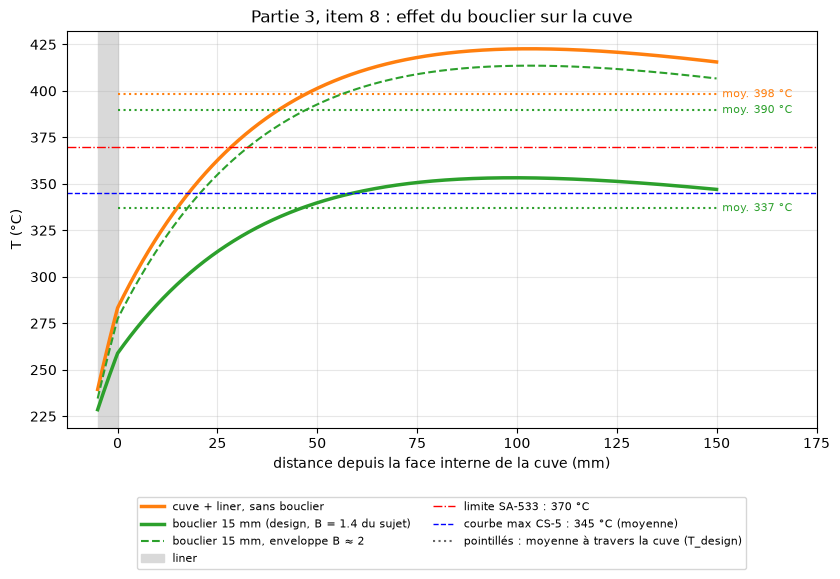

In [81]:
# ===== Partie 3, item 8 : items 5, 6, 8 et 9 de la Partie 1 refaits avec le bouclier =====
# Cas de dimensionnement : q0 contient déjà B = 1.4 (Table 1), appliqué à toute profondeur, bouclier compris :
#   q(d) = 1.4 mu phi E e^(-mu d) = q0 e^(-mu d)  ->  with_shield(..., B_sh=1)
# Enveloppe : B_sh = 1.4 réapplique le build-up dans le bouclier (B effectif ≈ 1.4 x 1.4 ≈ 2) : sensibilité.

# --- Table CS-5 (ASME II-D) : B(A, T), log-log en A sur chaque courbe, linéaire en T ---
if 'B_CS5' not in globals():
    CS5 = {
        40:  [(1.99e-4, 20.7), (1.60e-3, 169), (2e-3, 170), (3e-3, 171), (5e-3, 172), (6e-3, 172), (5e-2, 172)],
        95:  [(2.00e-4, 20.7), (1.57e-3, 162), (5e-2, 162)],
        150: [(2.03e-4, 20.7), (1.50e-3, 152), (3e-3, 155), (6e-3, 155), (5e-2, 155)],
        205: [(2.10e-4, 20.7), (1.54e-3, 143), (3e-3, 146), (7e-3, 152), (9e-3, 152), (1e-2, 154), (5e-2, 154)],
        290: [(2.15e-4, 20.7), (1.08e-3, 103), (2e-3, 113), (4e-3, 127), (1e-2, 138), (2e-2, 143), (5e-2, 147)],
        345: [(2.20e-4, 20.7), (1.21e-3, 103), (2e-3, 113), (4e-3, 123), (1e-2, 134), (5e-2, 143)],
    }
    def B_CS5(A, T):
        Ts = sorted(CS5)
        if not Ts[0] <= T <= Ts[-1]: raise ValueError(f"T = {T:.0f} °C hors de CS-5 (40-345 °C)")
        def B_at(Tc):
            a, b = np.array(CS5[Tc]).T
            return np.exp(np.interp(np.log(A), np.log(a), np.log(b)))
        i = min(np.searchsorted(Ts, T), len(Ts) - 1); T1, T2 = Ts[max(i - 1, 0)], Ts[i]
        if T == T2 or T1 == T2: return B_at(T2)
        return B_at(T1) + (T - T1)/(T2 - T1)*(B_at(T2) - B_at(T1))

T_CS5_max = 345.0
WS  = with_shield(R_s, t_s, 1.0)       # dimensionnement (build-up 1.4 du sujet, déjà dans q0)
WSb = with_shield(R_s, t_s, 1.4)       # enveloppe : build-up compté deux fois (B ≈ 2)
C_S, K_s, K_b = WS['sol'], WS['S'], WSb['S']

def q_faces(sol):
    # source volumique (MW/m3) à la surface mouillée, face interne et face externe de la cuve (profil du solveur, K0)
    rc, q = sol['rc'], sol['q']
    return q[0]/1e6, np.interp(R_i, rc, q)/1e6, q[-1]/1e6

# ---------------- item 5 : source gamma ----------------
print(f"Bouclier : t_s = {t_s*1e3:.0f} mm, R_s = {R_s*1e3:.0f} mm ; transmission e^(-mu t_s) = {WS['f']:.3f}"
      f" (enveloppe 1.4 e^(-mu t_s) = {WSb['f']:.3f})")
print("\nItem 5 : source gamma (MW/m3)")
print(f"{'':26}{'sans bouclier':>15}{'bouclier':>16}{'enveloppe B≈2':>14}")
for lab, j in (("surface mouillée", 0), ("face interne cuve", 1), ("face externe cuve", 2)):
    print(f"{lab:26}{q_faces(C_L)[j]:15.4f}{q_faces(C_S)[j]:16.4f}{q_faces(WSb['sol'])[j]:14.4f}")

# ---------------- item 6 : profil de température ----------------
print("\nItem 6 : températures de la cuve (°C)")
print(f"{'':28}{'sans bouclier':>15}{'bouclier':>16}{'enveloppe B≈2':>14}")
for lab, k in (("surface mouillée", 'T_w'), ("face interne cuve", 'T_i'), ("face externe cuve", 'T_o'),
               ("T_max cuve", 'T_max'), ("moyenne cuve", 'T_avg')):
    print(f"{lab:28}{c(K_L[k]):15.1f}{c(K_s[k]):16.1f}{c(K_b[k]):14.1f}")
print(f"{'position T_max (mm de R_i)':28}{K_L['x_max']*1e3:15.1f}{K_s['x_max']*1e3:16.1f}{K_b['x_max']*1e3:14.1f}")

# ---------------- item 8 : conditions de design ----------------
T_design_S = c(K_s['T_avg']); T_peak_S = c(K_s['T_max'])
ok_T = T_peak_S <= T_lim_fer and T_design_S <= T_CS5_max
print(f"\nItem 8 : T_design = {T_design_S:.1f} °C (sans bouclier : {c(K_L['T_avg']):.1f} °C ; Partie 0 : 292 °C provisoire)")
print(f"  pic {T_peak_S:.1f} °C <= {T_lim_fer:.0f} °C (NB-3112.4) et moyenne {T_design_S:.1f} °C <= {T_CS5_max:.0f} °C (CS-5)"
      f" -> {'OK' if ok_T else 'NON'} ; marges {T_lim_fer - T_peak_S:.0f} K et {T_CS5_max - T_design_S:.0f} K")
Sm_S = Sm_of(T_design_S); t_int_S = t_min_int(Sm_S)
print(f"  interne (NB-3324.1) : ligne {T_rows[row_of(T_design_S)]:.0f} °C, Sm = {Sm_S:.1f} MPa -> t_min = "
      f"{t_int_S*1e3:.1f} mm <= {t_v*1e3:.0f} mm -> {'OK' if t_int_S <= t_v else 'NON'}")
B_TD = B_CS5(A_chart, T_design_S)
print(f"  externe (NB-3133)   : A = {A_chart:.2e} (géométrie, inchangé) ; B({T_design_S:.0f} °C) = {B_TD:.1f} MPa (Table CS-5)"
      f" vs {B_req:.1f} MPa requis -> {'OK' if B_TD >= B_req else 'NON'} (marge {100*(B_TD/B_req - 1):+.1f} %)")
T_env = c(K_b['T_avg'])
print(f"  enveloppe B ≈ 2     : pic {c(K_b['T_max']):.1f} °C, moyenne {T_env:.1f} °C, B = {B_CS5(A_chart, min(T_env, T_CS5_max)):.1f} MPa"
      f" -> {'OK' if c(K_b['T_max']) <= T_lim_fer and T_env <= T_CS5_max and B_CS5(A_chart, min(T_env, T_CS5_max)) >= B_req else 'NON'}")
print(f"  -> épaisseur {'inchangée' if B_TD >= B_req and t_int_S <= t_v else 'à revoir'} : {t_v*1e3:.0f} mm, "
      f"toujours fixée par la pression externe")

# ---------------- item 9 : Level A ----------------
q_vi = q_faces(C_S)[1]*1e6                                  # source en face interne de la cuve
sQ_S = sigT*alpha_fer*E_fer*q_vi/(k_fer*(1 - nu_fer)*mu_fer**2)/1e6
Pm_S, PQ_S, tot_S = level_A(C_S, R_i, R_o, E_fer, alpha_fer, nu_fer, p_op, p_op)
three_Sm_S = 3*Sm_cycle(T_peak_S)
print(f"\nItem 9 : Level A (NB-3222), p = {p_op/1e6:.1f} MPa des deux côtés")
print(f"  Fig. 2 (borne haute, pic adiabatique) : {sQ_S:.0f} MPa")
print(f"  Pm (pression seule)     = {Pm_S:6.1f} MPa")
print(f"  Pm + Pb + Q (linéarisé) = {PQ_S:6.1f} MPa vs 3Sm = {three_Sm_S:.0f} MPa -> {'OK' if PQ_S <= three_Sm_S else 'NON'}"
      f"   (sans bouclier : {PQ:.1f} MPa)")
print(f"  pic total P + Q + F     = {tot_S:6.1f} MPa (fatigue, NB-3222.4)")

# ---------------- figure ----------------
fig, ax = plt.subplots(figsize=(8.5, 6))
for sol_, S_, col_, ls_, lw_, lab_ in ((C_L, K_L, 'tab:orange', '-', 2.5, 'cuve + liner, sans bouclier'),
                                       (C_S, K_s, 'tab:green', '-', 2.5, f'bouclier {t_s*1e3:.0f} mm (design, B = 1.4 du sujet)'),
                                       (WSb['sol'], K_b, 'tab:green', '--', 1.5, f'bouclier {t_s*1e3:.0f} mm, enveloppe B ≈ 2')):
    ax.plot(xr(sol_), c(sol_['T']), lw=lw_, ls=ls_, color=col_, label=lab_)
    # moyenne à travers la cuve (= T_design), tracée sur l'épaisseur de la cuve seulement
    ax.hlines(c(S_['T_avg']), 0, t_v*1e3, colors=col_, linestyles=':', lw=1.5)
    ax.annotate(f"moy. {c(S_['T_avg']):.0f} °C", (t_v*1e3, c(S_['T_avg'])), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=8, color=col_)
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner')
ax.axhline(T_lim_fer, color='red', ls='-.', lw=1, label='limite SA-533 : 370 °C')
ax.axhline(T_CS5_max, color='blue', ls='--', lw=1, label='courbe max CS-5 : 345 °C (moyenne)')
ax.set_xlabel('distance depuis la face interne de la cuve (mm)'); ax.set_ylabel('T (°C)')
ax.plot([], [], ls=':', color='0.4', label='pointillés : moyenne à travers la cuve (T_design)')
ax.set_xlim(right=t_v*1e3 + 25)
ax.set_title('Partie 3, item 8 : effet du bouclier sur la cuve'); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2); plt.tight_layout()
plt.show()

**Conclusion de la Partie 3.** Avec un bouclier de 30 mm, la cuve passe sous 370 °C avec une large marge ; la température de design tombe à environ 300 °C, au voisinage de la valeur provisoire. L'épaisseur de **150 mm est conservée** : la pression interne n'est pas dimensionnante, et en externe il faut seulement vérifier sur CS-5 que $B$ à la nouvelle température de design reste au-dessus de la valeur requise affichée. Les contraintes Level A de la cuve et du bouclier sont admissibles.

In [82]:
# ===== Partie 3 : bouclier de 13 mm (épaisseur minimale, modèle de design B = 1.4 dans q0) =====
# Puis re-dimensionnement de la cuve en pression externe (NB-3133) : T_D, A et B dépendent de l'épaisseur.
if 'B_CS5' not in globals():
    CS5 = {
        40:  [(1.99e-4, 20.7), (1.60e-3, 169), (2e-3, 170), (3e-3, 171), (5e-3, 172), (6e-3, 172), (5e-2, 172)],
        95:  [(2.00e-4, 20.7), (1.57e-3, 162), (5e-2, 162)],
        150: [(2.03e-4, 20.7), (1.50e-3, 152), (3e-3, 155), (6e-3, 155), (5e-2, 155)],
        205: [(2.10e-4, 20.7), (1.54e-3, 143), (3e-3, 146), (7e-3, 152), (9e-3, 152), (1e-2, 154), (5e-2, 154)],
        290: [(2.15e-4, 20.7), (1.08e-3, 103), (2e-3, 113), (4e-3, 127), (1e-2, 138), (2e-2, 143), (5e-2, 147)],
        345: [(2.20e-4, 20.7), (1.21e-3, 103), (2e-3, 113), (4e-3, 123), (1e-2, 134), (5e-2, 143)],
    }
    def B_CS5(A, T):
        Ts = sorted(CS5)
        if not Ts[0] <= T <= Ts[-1]: raise ValueError(f"T = {T:.0f} °C hors de CS-5 (40-345 °C)")
        def B_at(Tc):
            a, b = np.array(CS5[Tc]).T
            return np.exp(np.interp(np.log(A), np.log(a), np.log(b)))
        i = min(np.searchsorted(Ts, T), len(Ts) - 1); T1, T2 = Ts[max(i - 1, 0)], Ts[i]
        if T == T2 or T1 == T2: return B_at(T2)
        return B_at(T1) + (T - T1)/(T2 - T1)*(B_at(T2) - B_at(T1))

t_s13, R_s13 = 0.013, 1.36            # m ; R_s sans effet sur la cuve, même valeur que les cas Z3ST
W13 = with_shield(R_s13, t_s13)       # design : B = 1.4 déjà dans q0
f13, h13 = W13['f'], W13['co']['h']
print(f"Bouclier {t_s13*1e3:.0f} mm : transmission e^(-mu t_s) = {f13:.3f}, source surface mouillée "
      f"{f13*q0/1e6:.3f} MW/m3, h canal côté liner = {h13:.0f} W/m2K")

# --- A en fonction de l'épaisseur : lectures Fig. G du tableau 'tab' (Partie 1, item 3b), loi puissance ---
# A ne dépend que de la géométrie (L_u/D_o, D_o/t). Au-delà de 150 mm : extrapolation, à vérifier sur Fig. G.
pA = np.polyfit(np.log(tab["t [mm]"]), np.log(tab["A [1e-3]"]*1e-3), 1)
A_of = lambda t_mm: float(np.exp(np.polyval(pA, np.log(t_mm))))

print(f"\nPression externe, bouclier {t_s13*1e3:.0f} mm, p_D,ext = {p_D_ext/1e6:.2f} MPa")
print(f"{'t cuve':>7}{'T_D °C':>9}{'pic °C':>9}{'D_o/t':>8}{'A':>10}{'B MPa':>8}{'P_a MPa':>9}{'marge':>8}  verdict")
rows13 = []
for tv_mm in range(140, 171, 5):
    tv = tv_mm*1e-3
    sol_ = solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (tv, k_fer, mu_fer)], f13*q0, h13, U2)
    S_ = summary_cyl(sol_, R_i)
    TD, Tpk = c(S_['T_avg']), c(S_['T_max'])
    Do_ = 2*(R_i + tv); Dot = Do_/tv; A_ = A_of(tv_mm)
    if TD <= 345.0:
        B_ = B_CS5(A_, TD); Pa = 4*B_/(3*Dot); m = Pa*1e6/p_D_ext - 1
        ok = Pa*1e6 >= p_D_ext and Tpk <= T_lim_fer
        verdict = 'OK' if ok else 'NON'
    else:
        B_ = Pa = m = np.nan; ok = False; verdict = 'T_D > 345 °C : hors CS-5'
    rows13.append(dict(t=tv_mm, TD=TD, Tpk=Tpk, A=A_, B=B_, Pa=Pa, ok=ok))
    print(f"{tv_mm:7d}{TD:9.1f}{Tpk:9.1f}{Dot:8.2f}{A_:10.2e}{B_:8.1f}{Pa:9.3f}{100*m:+7.1f}%  {verdict}"
          + ("   (A extrapolé)" if tv_mm > 150 else ""))

ok13 = [r['t'] for r in rows13 if r['ok']]
print(f"\n-> épaisseurs de cuve admissibles avec le bouclier de {t_s13*1e3:.0f} mm : "
      + (", ".join(f"{t} mm" for t in ok13) if ok13 else "aucune dans la plage"))
print("   Une cuve plus épaisse a un A plus grand (meilleure tenue) mais absorbe plus de gammas : T_D monte")
print("   vers 345 °C, où B baisse puis devient illisible. Le design est pris en étau entre les deux.")
r150 = next(r for r in rows13 if r['t'] == 150)
print(f"\nCuve 150 mm : T_D = {r150['TD']:.1f} °C (marge {345 - r150['TD']:.1f} K sur CS-5), "
      f"P_a = {r150['Pa']:.3f} MPa (marge {100*(r150['Pa']*1e6/p_D_ext - 1):+.1f} %)")
print(f"   interne : Sm({r150['TD']:.0f} °C) = {Sm_of(r150['TD']):.1f} MPa -> t_min = {t_min_int(Sm_of(r150['TD']))*1e3:.1f} mm -> OK")

Bouclier 13 mm : transmission e^(-mu t_s) = 0.732, source surface mouillée 3.546 MW/m3, h canal côté liner = 9001 W/m2K

Pression externe, bouclier 13 mm, p_D,ext = 7.55 MPa
 t cuve   T_D °C   pic °C   D_o/t         A   B MPa  P_a MPa   marge  verdict
    140    340.6    358.2   23.50  4.54e-03   124.8    7.080   -6.2%  NON
    145    342.1    359.5   22.76  4.78e-03   125.3    7.339   -2.8%  NON
    150    343.5    360.8   22.07  5.03e-03   125.8    7.599   +0.6%  OK
    155    344.8    361.9   21.42  5.28e-03   126.2    7.858   +4.1%  OK   (A extrapolé)
    160    345.9    362.9   20.81  5.53e-03     nan      nan   +nan%  T_D > 345 °C : hors CS-5   (A extrapolé)
    165    346.9    363.8   20.24  5.79e-03     nan      nan   +nan%  T_D > 345 °C : hors CS-5   (A extrapolé)
    170    347.9    364.6   19.71  6.05e-03     nan      nan   +nan%  T_D > 345 °C : hors CS-5   (A extrapolé)

-> épaisseurs de cuve admissibles avec le bouclier de 13 mm : 150 mm, 155 mm
   Une cuve plus épaisse a 

Avec l'épaisseur minimale du bouclier (13 mm), la cuve n'est admissible que pour 150 à 155 mm, avec au mieux 1,5 K de marge sur la limite de lecture de CS-5 et 0,6 % sur la pression externe admissible : une épaisseur de cuve plus forte élève T_D au-delà de 345 °C, une plus faible ne tient pas la pression. On retient donc un bouclier plus épais que le minimum.


=== Bouclier 13 mm : transmission 0.732, source surface mouillée 3.546 MW/m3, h côté liner 9001 W/m2K ; p_D,ext = 7.55 MPa
 t cuve   T_D °C   pic °C   D_o/t         A   B MPa  P_a MPa  marge P_a  marge T_D  verdict
    140    340.6    358.2   23.50  4.54e-03   124.8    7.080      -6.2%     +4.4 K  NON
    145    342.1    359.5   22.76  4.78e-03   125.3    7.339      -2.8%     +2.9 K  NON
    150    343.5    360.8   22.07  5.03e-03   125.8    7.599      +0.6%     +1.5 K  OK
    155    344.8    361.9   21.42  5.28e-03   126.2    7.858      +4.1%     +0.2 K  OK   (A extrapolé)
    160    345.9    362.9   20.81  5.53e-03     nan      nan      +nan%     -0.9 K  hors CS-5 (T_D > 345 °C)   (A extrapolé)
    165    346.9    363.8   20.24  5.79e-03     nan      nan      +nan%     -1.9 K  hors CS-5 (T_D > 345 °C)   (A extrapolé)
    170    347.9    364.6   19.71  6.05e-03     nan      nan      +nan%     -2.9 K  hors CS-5 (T_D > 345 °C)   (A extrapolé)
-> cuves admissibles : 150 à 155 mm

=== Bo

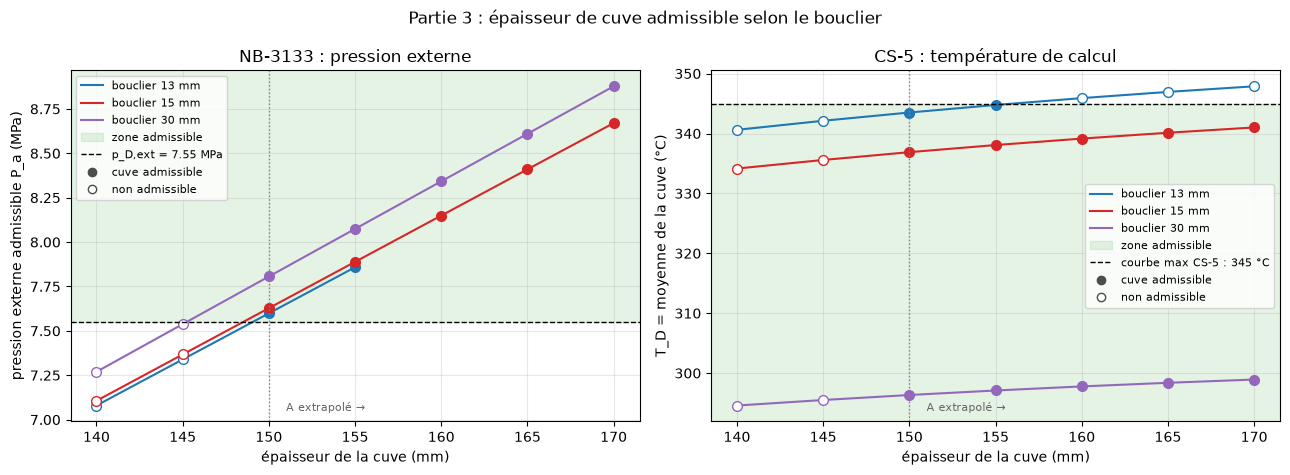

In [83]:
# ===== Partie 3 : épaisseur de la cuve en pression externe (NB-3133) selon l'épaisseur du bouclier =====
# Modèle de design : B = 1.4 déjà dans q0. Pour chaque bouclier et chaque épaisseur de cuve :
# T_D (moyenne) et pic par la thermique, A (Fig. G, géométrie), B (Table CS-5 à T_D), P_a = 4B/(3 D_o/t).
if 'B_CS5' not in globals():
    CS5 = {
        40:  [(1.99e-4, 20.7), (1.60e-3, 169), (2e-3, 170), (3e-3, 171), (5e-3, 172), (6e-3, 172), (5e-2, 172)],
        95:  [(2.00e-4, 20.7), (1.57e-3, 162), (5e-2, 162)],
        150: [(2.03e-4, 20.7), (1.50e-3, 152), (3e-3, 155), (6e-3, 155), (5e-2, 155)],
        205: [(2.10e-4, 20.7), (1.54e-3, 143), (3e-3, 146), (7e-3, 152), (9e-3, 152), (1e-2, 154), (5e-2, 154)],
        290: [(2.15e-4, 20.7), (1.08e-3, 103), (2e-3, 113), (4e-3, 127), (1e-2, 138), (2e-2, 143), (5e-2, 147)],
        345: [(2.20e-4, 20.7), (1.21e-3, 103), (2e-3, 113), (4e-3, 123), (1e-2, 134), (5e-2, 143)],
    }
    def B_CS5(A, T):
        Ts = sorted(CS5)
        if not Ts[0] <= T <= Ts[-1]: raise ValueError(f"T = {T:.0f} °C hors de CS-5 (40-345 °C)")
        def B_at(Tc):
            a, b = np.array(CS5[Tc]).T
            return np.exp(np.interp(np.log(A), np.log(a), np.log(b)))
        i = min(np.searchsorted(Ts, T), len(Ts) - 1); T1, T2 = Ts[max(i - 1, 0)], Ts[i]
        if T == T2 or T1 == T2: return B_at(T2)
        return B_at(T1) + (T - T1)/(T2 - T1)*(B_at(T2) - B_at(T1))

def balayage_cuve(t_sh, R_sh=1.36, tv_list=range(140, 171, 5)):
    # A(t) : lectures Fig. G du tableau 'tab' (Partie 1, item 3b), loi puissance ; > 150 mm : extrapolé
    pA = np.polyfit(np.log(tab["t [mm]"]), np.log(tab["A [1e-3]"]*1e-3), 1)
    W = with_shield(R_sh, t_sh)
    out = []
    for tv_mm in tv_list:
        tv = tv_mm*1e-3
        S = summary_cyl(solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (tv, k_fer, mu_fer)], W['f']*q0, W['co']['h'], U2), R_i)
        TD, Tpk = c(S['T_avg']), c(S['T_max'])
        Dot = 2*(R_i + tv)/tv; A = float(np.exp(np.polyval(pA, np.log(tv_mm))))
        B = B_CS5(A, TD) if TD <= 345.0 else np.nan
        Pa = 4*B/(3*Dot)
        ok = bool(TD <= 345.0 and Tpk <= T_lim_fer and Pa*1e6 >= p_D_ext)
        out.append(dict(tv=tv_mm, TD=TD, Tpk=Tpk, Dot=Dot, A=A, B=B, Pa=Pa, mPa=100*(Pa*1e6/p_D_ext - 1),
                        mT=345.0 - TD, ok=ok))
    return W, out

BOUCLIERS = (0.013, 0.015, 0.030)            # m, ajouter d'autres épaisseurs si besoin (0.020, 0.030, ...)
RES = {}
for t_sh in BOUCLIERS:
    W, rows_ = balayage_cuve(t_sh)
    RES[t_sh] = rows_
    print(f"\n=== Bouclier {t_sh*1e3:.0f} mm : transmission {W['f']:.3f}, source surface mouillée {W['f']*q0/1e6:.3f} MW/m3, "
          f"h côté liner {W['co']['h']:.0f} W/m2K ; p_D,ext = {p_D_ext/1e6:.2f} MPa")
    print(f"{'t cuve':>7}{'T_D °C':>9}{'pic °C':>9}{'D_o/t':>8}{'A':>10}{'B MPa':>8}{'P_a MPa':>9}{'marge P_a':>11}"
          f"{'marge T_D':>11}  verdict")
    for r in rows_:
        verdict = 'OK' if r['ok'] else ('hors CS-5 (T_D > 345 °C)' if r['TD'] > 345 else 'NON')
        print(f"{r['tv']:7d}{r['TD']:9.1f}{r['Tpk']:9.1f}{r['Dot']:8.2f}{r['A']:10.2e}{r['B']:8.1f}{r['Pa']:9.3f}"
              f"{r['mPa']:+10.1f}%{r['mT']:+9.1f} K  {verdict}" + ("   (A extrapolé)" if r['tv'] > 150 else ""))
    oks = [r['tv'] for r in rows_ if r['ok']]
    print(f"-> cuves admissibles : " + (f"{min(oks)} à {max(oks)} mm" if oks else "aucune dans la plage"))

# --- synthèse à 150 mm ---
print(f"\nSynthèse, cuve de 150 mm :")
print(f"{'bouclier':>10}{'T_D °C':>9}{'marge T_D':>11}{'P_a MPa':>9}{'marge P_a':>11}")
for t_sh, rows_ in RES.items():
    r = next(r for r in rows_ if r['tv'] == 150)
    print(f"{t_sh*1e3:8.0f} mm{r['TD']:9.1f}{r['mT']:+9.1f} K{r['Pa']:9.3f}{r['mPa']:+10.1f}%")

# --- figure : les deux critères en fonction de l'épaisseur de cuve, une couleur par bouclier ---
# zone verte = côté admissible du critère ; point plein = cuve admissible (tous critères), point creux = non admissible
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
COLS = ('tab:blue', 'tab:red', 'tab:purple', 'tab:orange', 'tab:brown', 'tab:gray')   # pas de vert : réservé aux zones
for (t_sh, rows_), col in zip(RES.items(), COLS):
    tv_ = np.array([r['tv'] for r in rows_]); ok_ = np.array([r['ok'] for r in rows_])
    axs[0].plot(tv_, [r['Pa'] for r in rows_], '-', color=col, label=f'bouclier {t_sh*1e3:.0f} mm')
    axs[1].plot(tv_, [r['TD'] for r in rows_], '-', color=col, label=f'bouclier {t_sh*1e3:.0f} mm')
    for ax_, key in ((axs[0], 'Pa'), (axs[1], 'TD')):
        y_ = np.array([r[key] for r in rows_])
        ax_.plot(tv_[ok_], y_[ok_], 'o', color=col, ms=7)
        ax_.plot(tv_[~ok_], y_[~ok_], 'o', mfc='white', mec=col, ms=7)
for ax_, lim, below, lab in ((axs[0], p_D_ext/1e6, False, f'p_D,ext = {p_D_ext/1e6:.2f} MPa'),
                             (axs[1], 345.0, True, 'courbe max CS-5 : 345 °C')):
    ax_.relim(); ax_.autoscale_view(); y0, y1 = ax_.get_ylim()
    ax_.axhspan(y0 if below else lim, lim if below else y1, color='tab:green', alpha=0.12, zorder=0, label='zone admissible')
    ax_.axhline(lim, color='k', ls='--', lw=1, label=lab); ax_.set_ylim(y0, y1)
    ax_.axvline(150, color='0.5', ls=':', lw=1)
    ax_.text(151, y0 + 0.03*(y1 - y0), 'A extrapolé →', fontsize=8, color='0.4')
    ax_.set_xlabel('épaisseur de la cuve (mm)'); ax_.grid(alpha=0.3)
    ax_.plot([], [], 'o', color='0.3', label='cuve admissible'); ax_.plot([], [], 'o', mfc='white', mec='0.3', label='non admissible')
    ax_.legend(fontsize=8)
axs[0].set_ylabel('pression externe admissible P_a (MPa)'); axs[0].set_title('NB-3133 : pression externe')
axs[1].set_ylabel('T_D = moyenne de la cuve (°C)'); axs[1].set_title('CS-5 : température de calcul')
plt.suptitle('Partie 3 : épaisseur de cuve admissible selon le bouclier'); plt.tight_layout(); plt.show()

Le bouclier ramène la température de calcul de 402 à environ 296 °C, soit pratiquement la valeur provisoire de la Partie 0 (292 °C) qui avait servi à dimensionner la cuve. La pression externe, qui gouverne l’épaisseur, ne dépend de la température que par B, qui varie de 3 % seulement entre 290 et 345 °C. L’épaisseur ne pourrait donc diminuer que de 4 à 5 mm. On conserve 150 mm, ce qui garde une marge d’environ 3 % sur la pression externe.

---
## Annexe : figures Z3ST

Figures produites par Z3ST (`check.py`, `compare_stress.py`) dans `~/z3st/nudet/<cas>/output/`, regroupées par item. Les comparaisons chiffrées sont aux items 6 (température), 9 (contraintes) et en Partie 3 (bouclier).

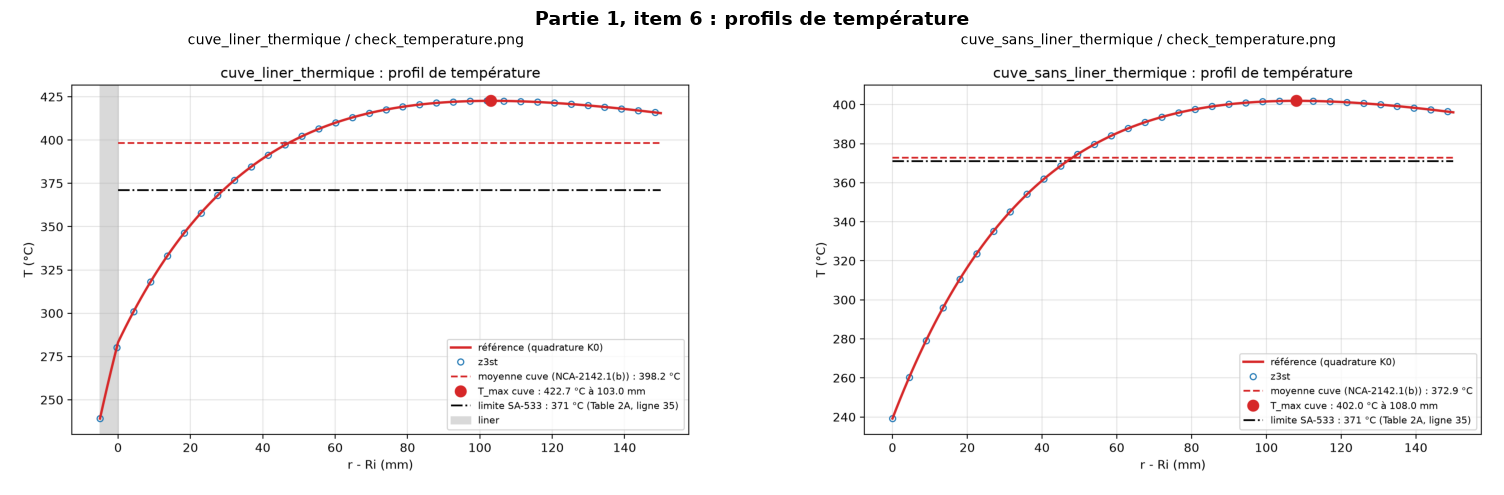

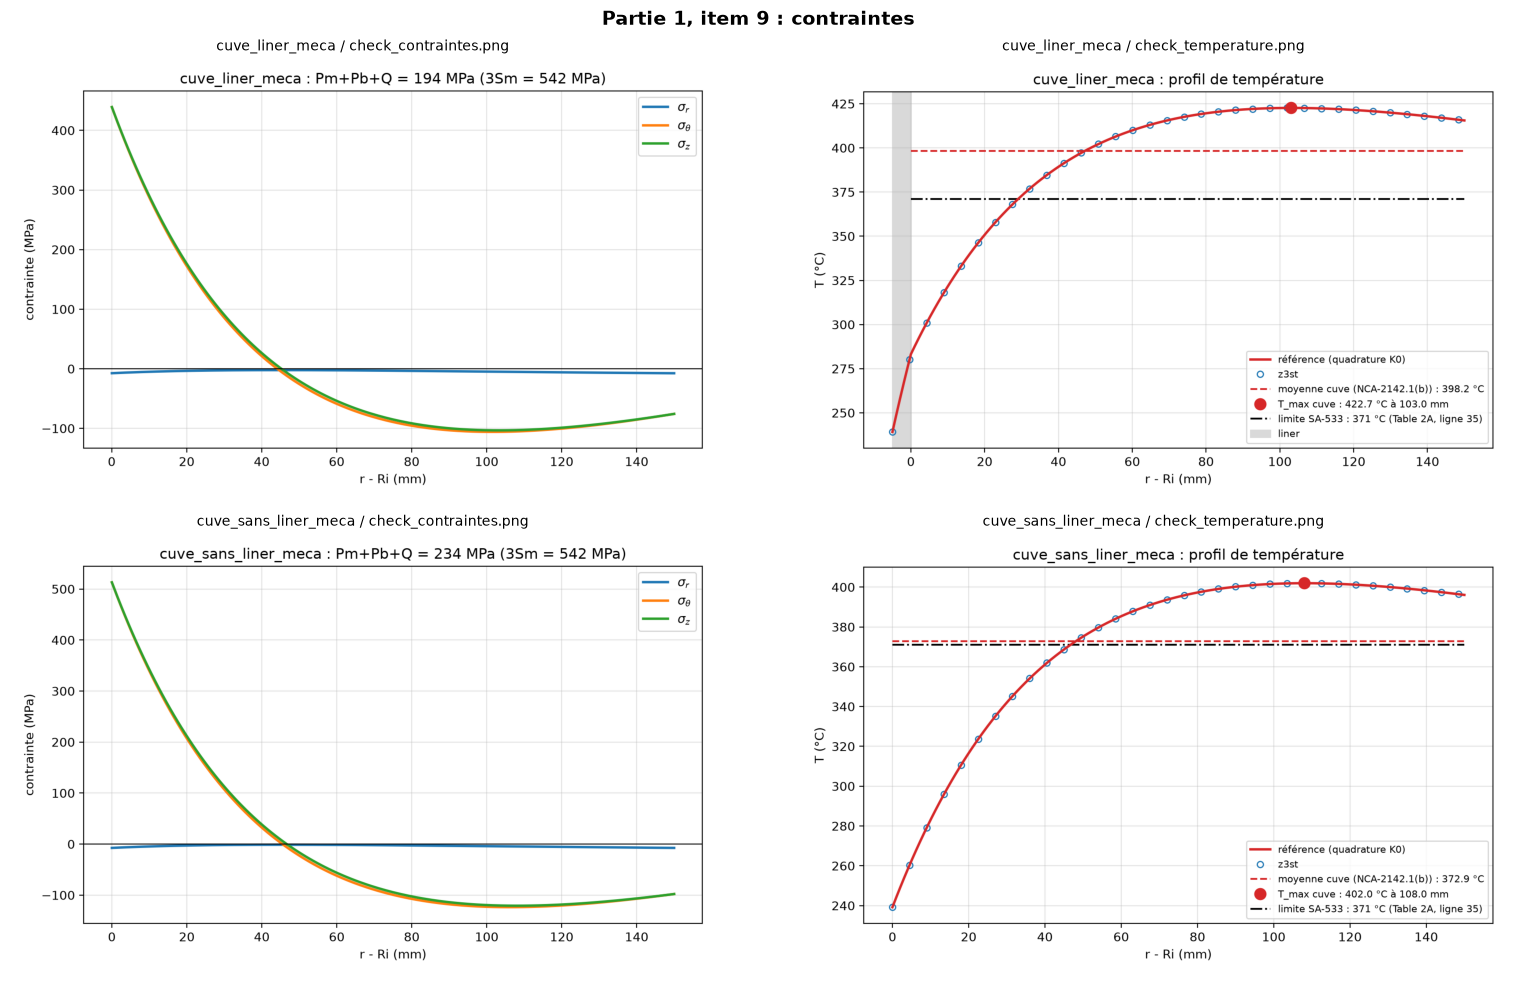

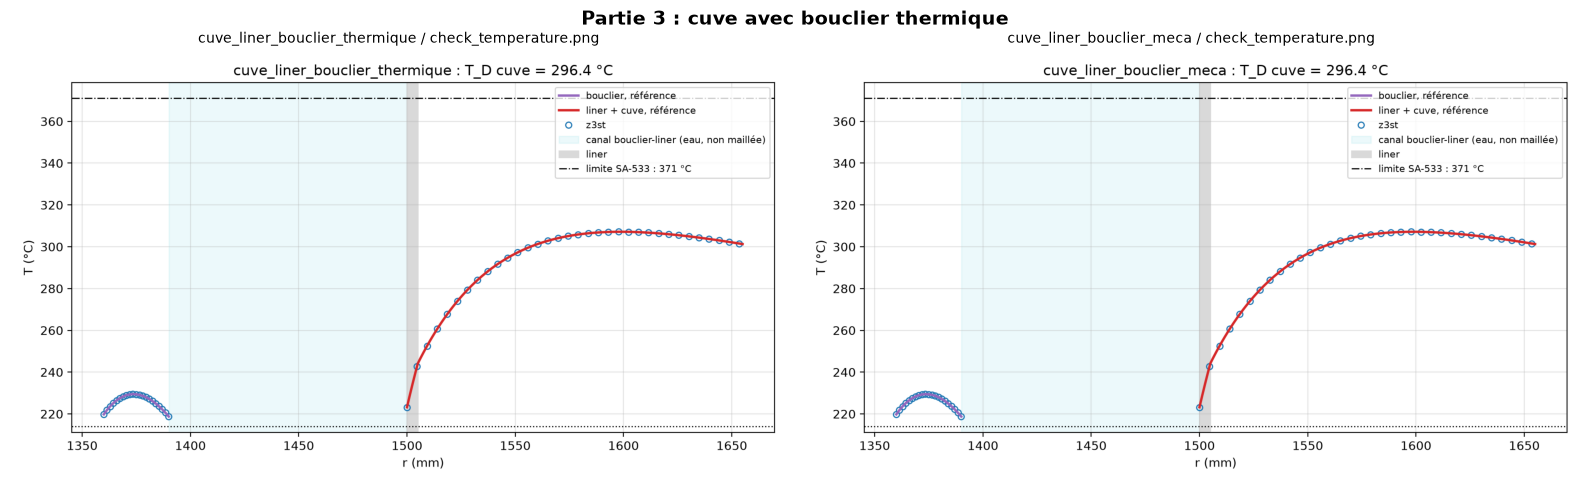

In [84]:
# ===== Annexe : figures produites par Z3ST (check.py / compare_stress.py) =====
import glob
import matplotlib.image as mpimg

Z3ST_NUDET = os.path.expanduser('~/z3st/nudet')
GROUPES = [
    ("Partie 1, item 6 : profils de température", ['cuve_liner_thermique', 'cuve_sans_liner_thermique']),
    ("Partie 1, item 9 : contraintes",            ['cuve_liner_meca', 'cuve_sans_liner_meca']),
    ("Partie 3 : cuve avec bouclier thermique",    ['cuve_liner_bouclier_thermique', 'cuve_liner_bouclier_meca']),
]

for titre, cas in GROUPES:
    figs = [(c_, f) for c_ in cas for f in sorted(glob.glob(os.path.join(Z3ST_NUDET, c_, 'output', '*.png')))]
    if not figs:
        print(f"{titre} : aucune figure trouvée dans {', '.join(cas)}"); continue
    n = len(figs); nc = min(n, 2); nr = -(-n//nc)
    fig, axs = plt.subplots(nr, nc, figsize=(8*nc, 5*nr), squeeze=False)
    for ax in axs.flat: ax.axis('off')
    for ax, (c_, f) in zip(axs.flat, figs):
        ax.imshow(mpimg.imread(f))
        ax.set_title(f"{c_} / {os.path.basename(f)}", fontsize=10)
    fig.suptitle(titre, fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()